In [9]:
import cPickle as pickle
import os
import time

import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sparse
from sklearn.decomposition import PCA
from sklearn.mixture import BayesianGaussianMixture

from neo.core import SpikeTrain, Unit, Segment, Block, ChannelIndex

from config import config

from spikes.sorting.clustering import GaussianMixtureClustererPruned
from spikes.sorting import collect_waveforms, binned_spikes
from spikes.sorting.binary_pursuit import make_V, pursue, pursue_iter
from spikes.plotting import raster, plot_spikes_with_timeseries

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [10]:
DATADIR = config.get("project", "datadir")

In [11]:
data_path = os.path.join(DATADIR, "LbY6074__161215_145633-thresholded.pkl")

In [5]:
with open(data_path, "rb") as datafile:
    block = pickle.load(datafile)
block.create_relationship(recursive=True, force=True, append=True)

In [6]:
spikes_path = os.path.join(DATADIR, "LbY6074__161215_145633-sorted.pkl")
with open(spikes_path, "rb") as datafile:
    spikes_block = pickle.load(datafile)
spikes_block.create_relationship(recursive=True, force=True, append=True)

student_song_0
0


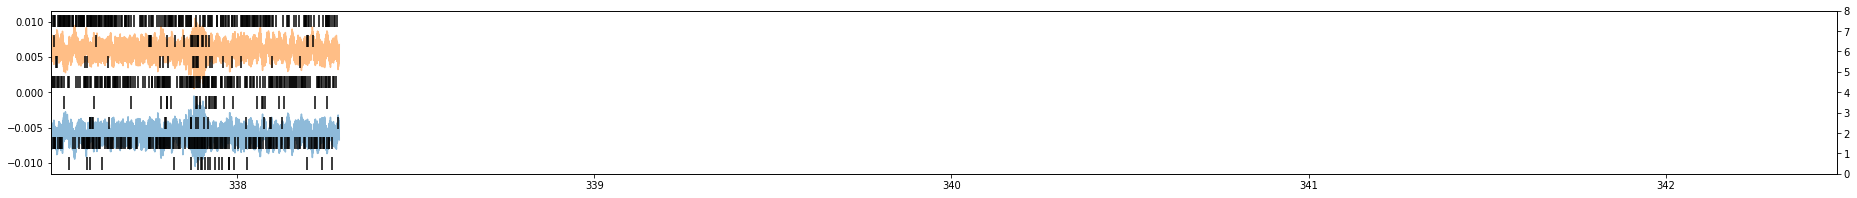

student_song_1
1


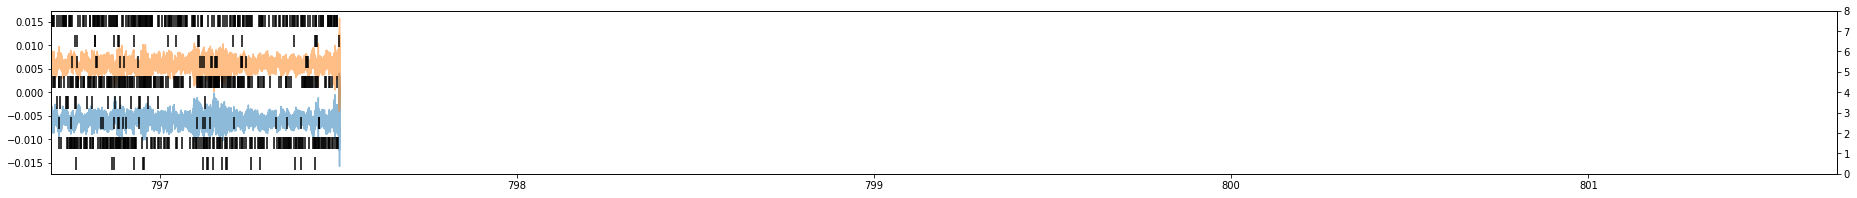

student_song_2
2


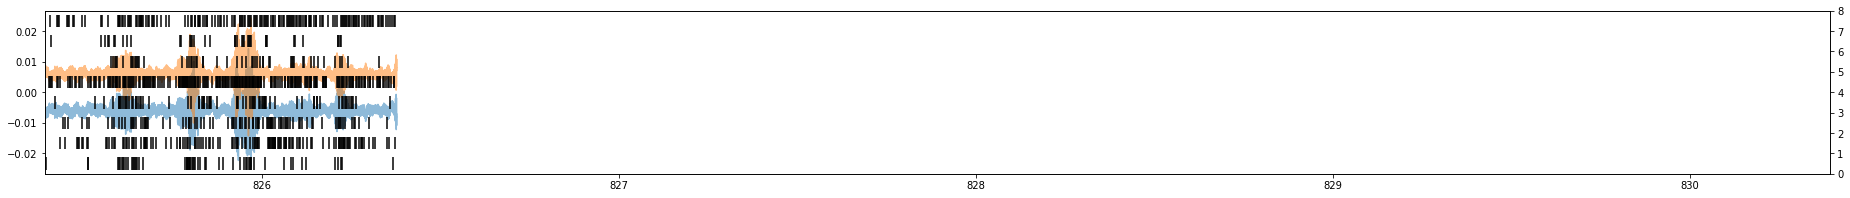

student_song_3
3


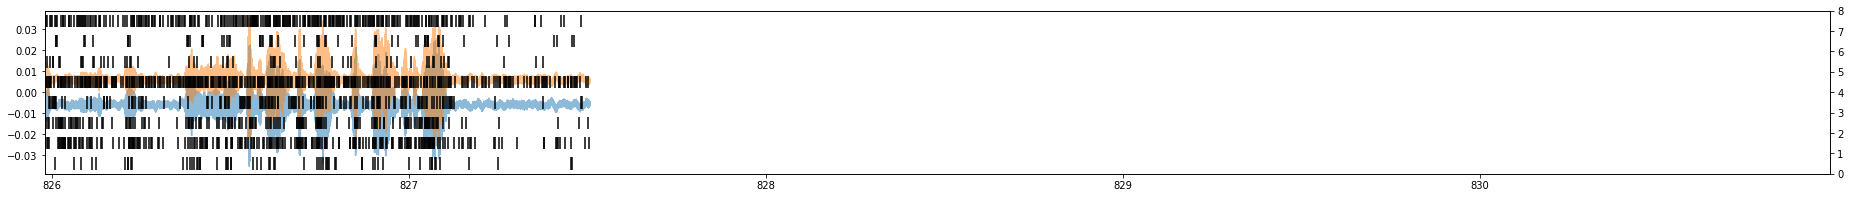

student_song_4
4


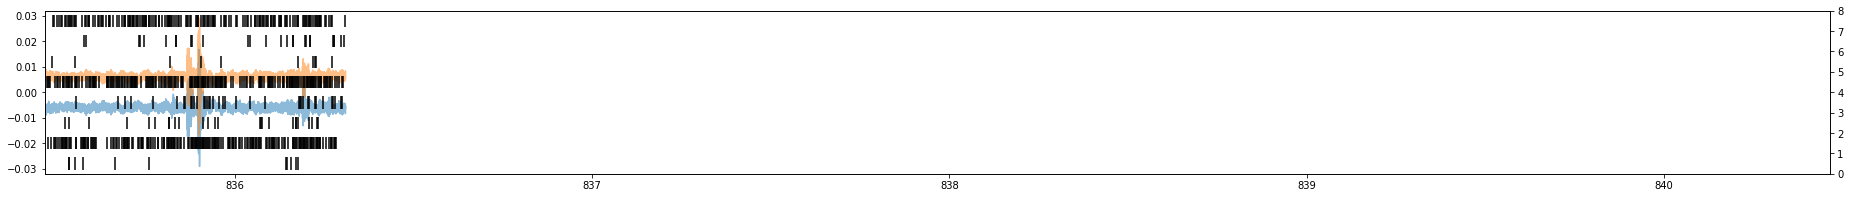

student_song_5
5


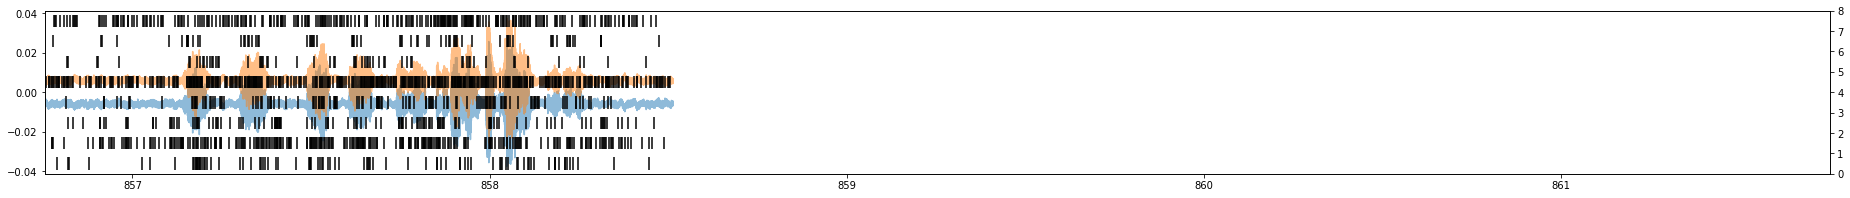

student_song_6
6


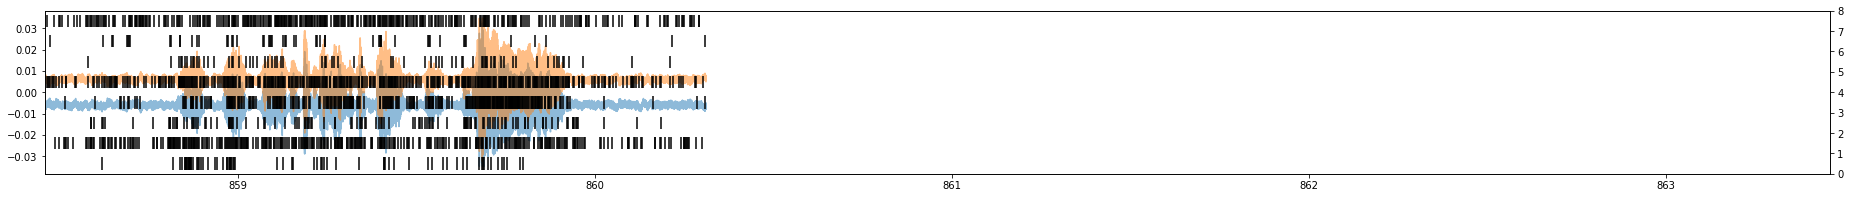

student_song_7
7


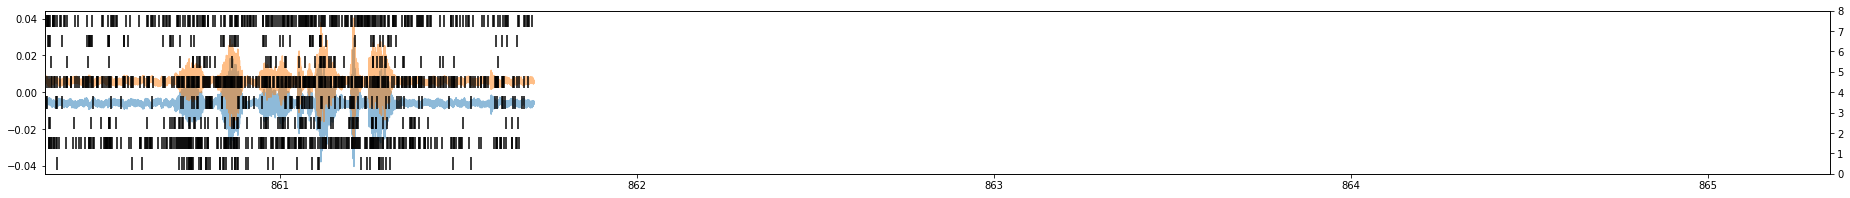

student_song_8
8


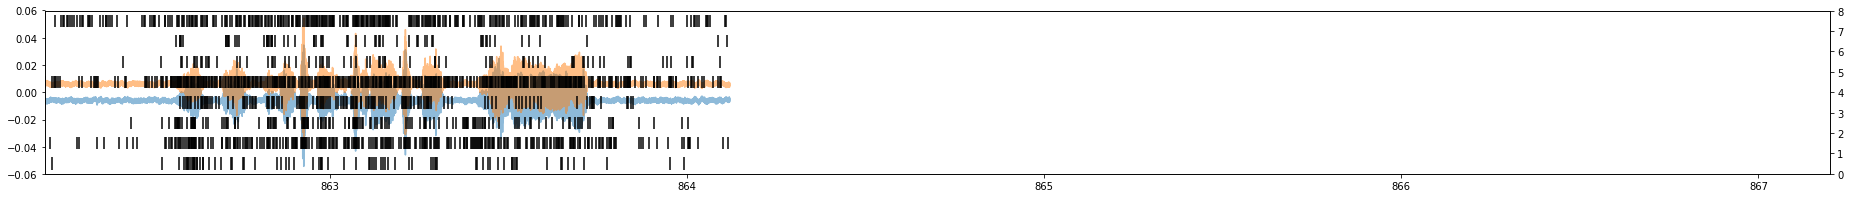

student_song_9
9


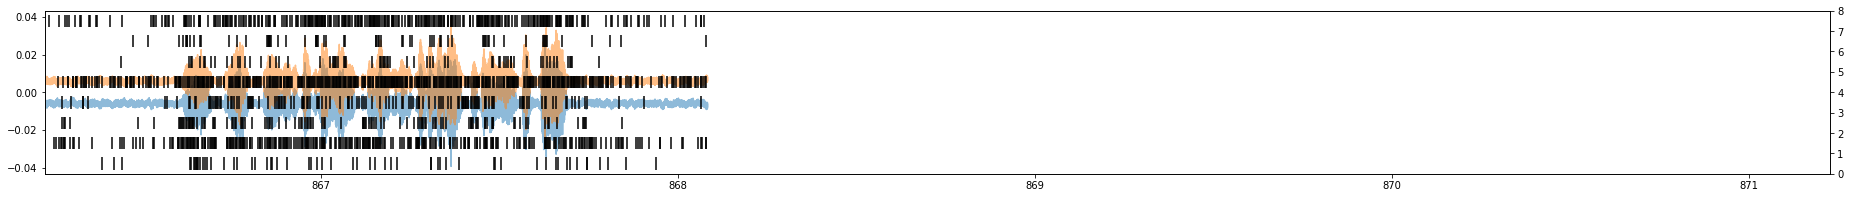

student_song_10
10


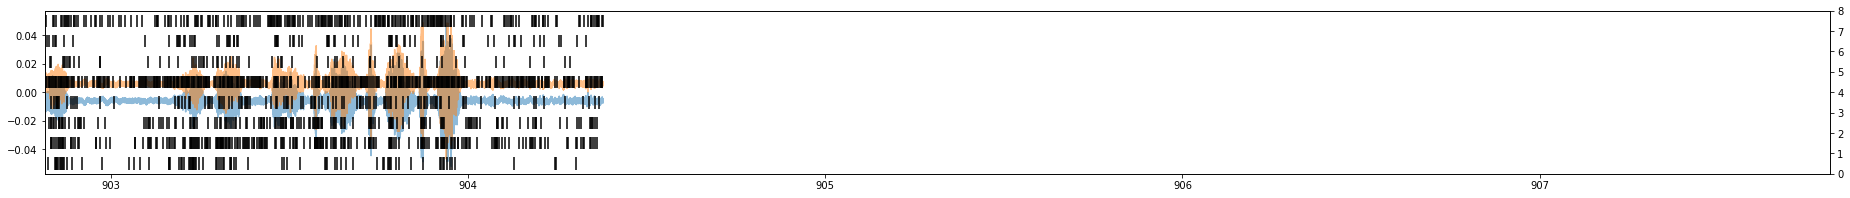

student_song_11
11


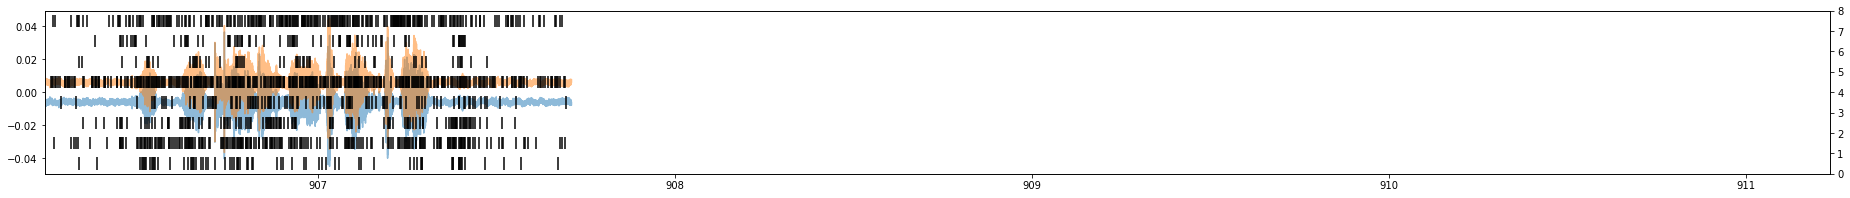

student_song_12
12


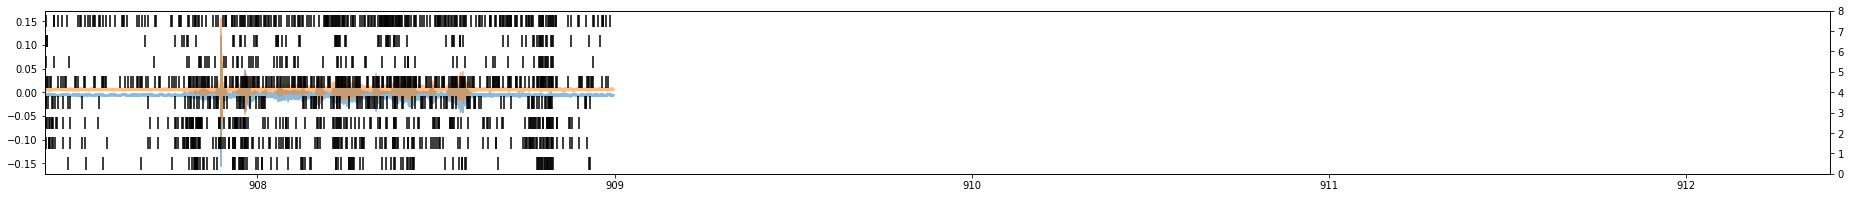

student_song_13
13


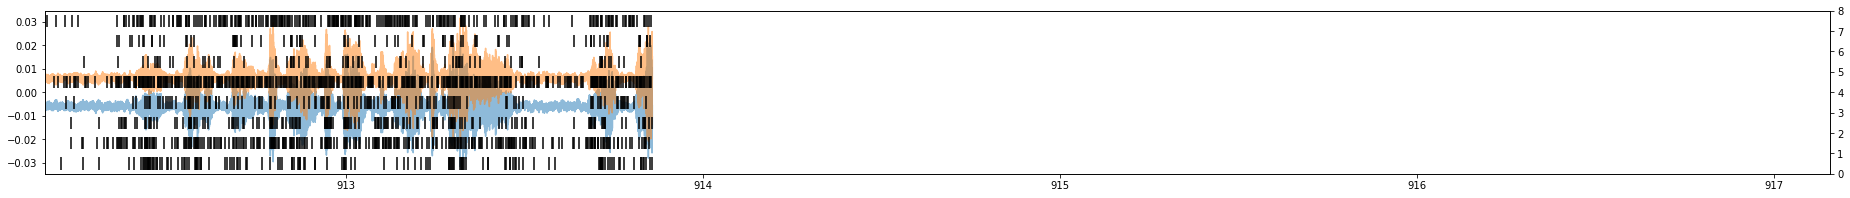

student_song_14
14


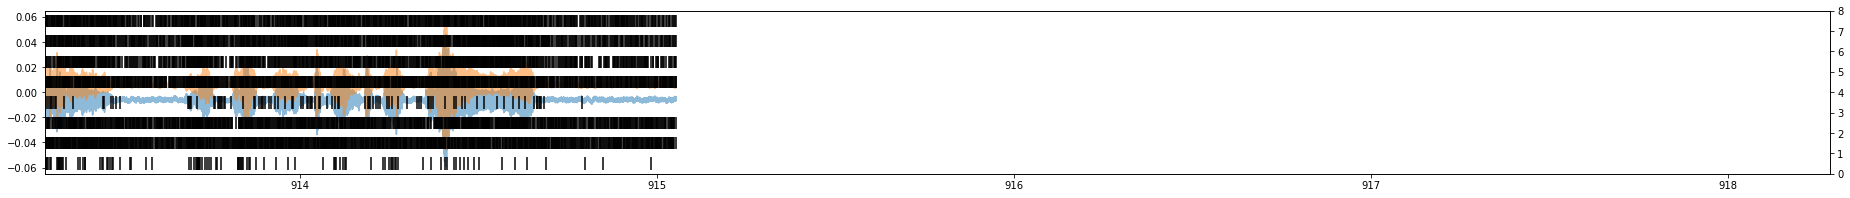

student_song_15
15


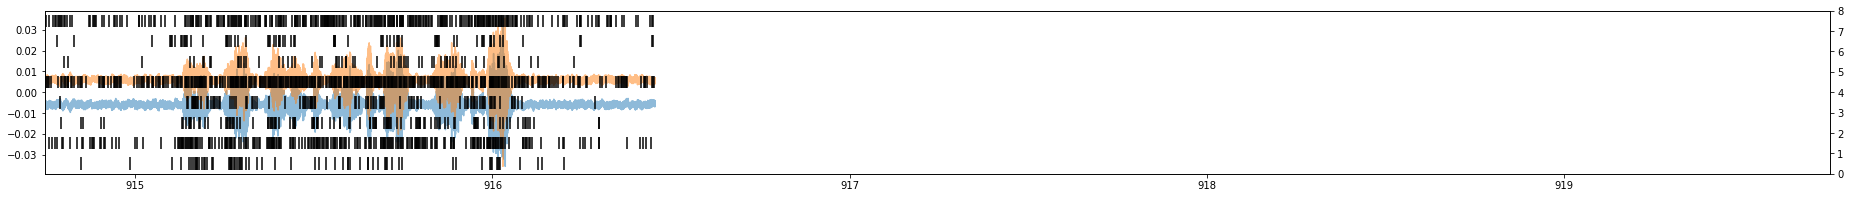

student_song_16
16


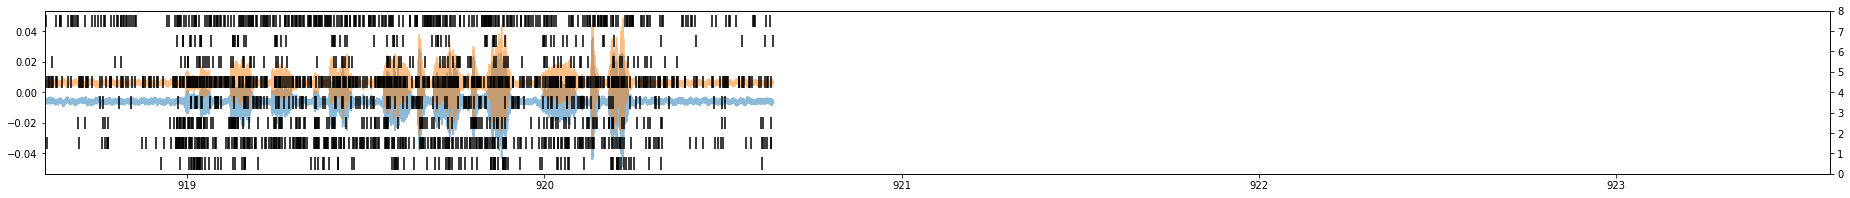

student_song_17
17


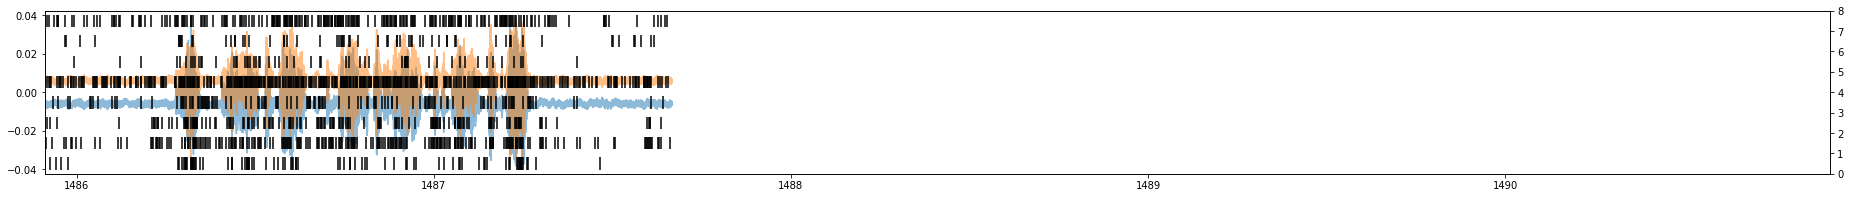

student_song_18
18


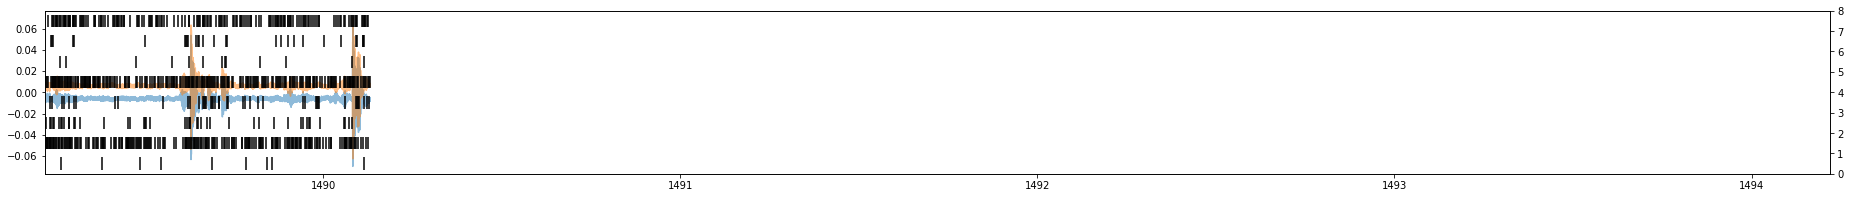

student_song_19
19


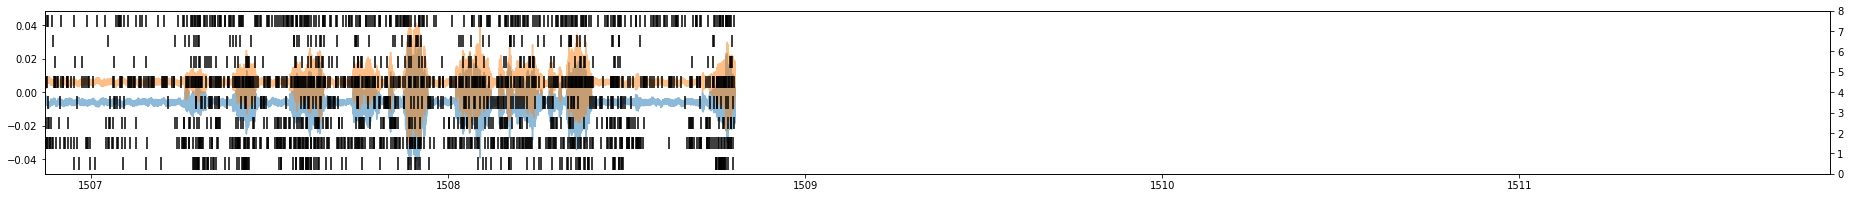

student_song_20
20


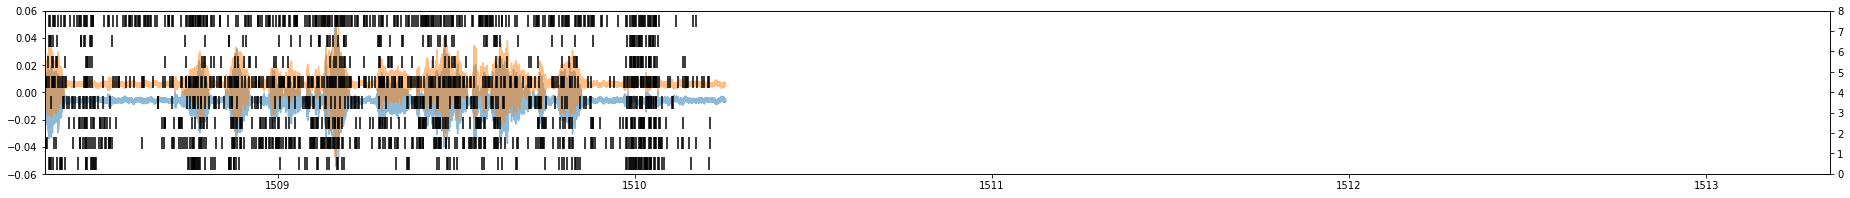

student_song_21
21


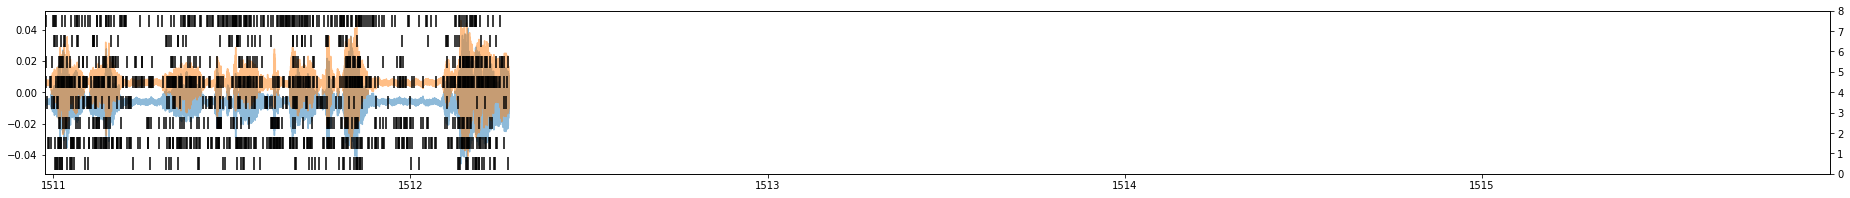

student_song_22
22


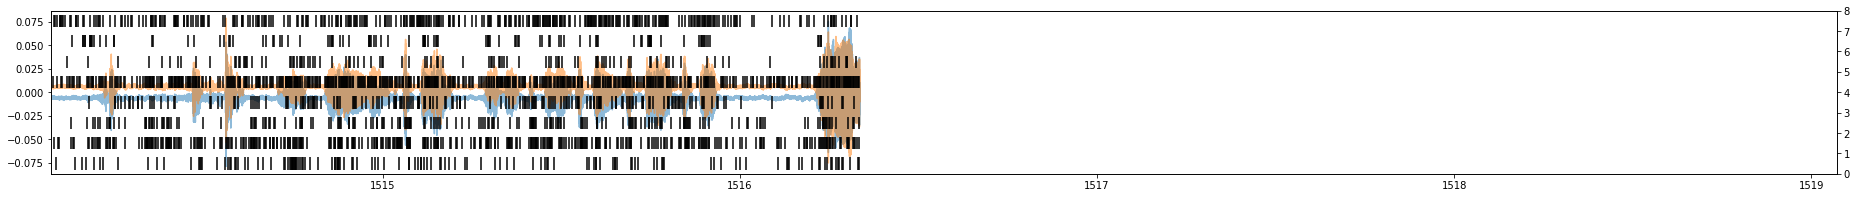

student_song_23
23


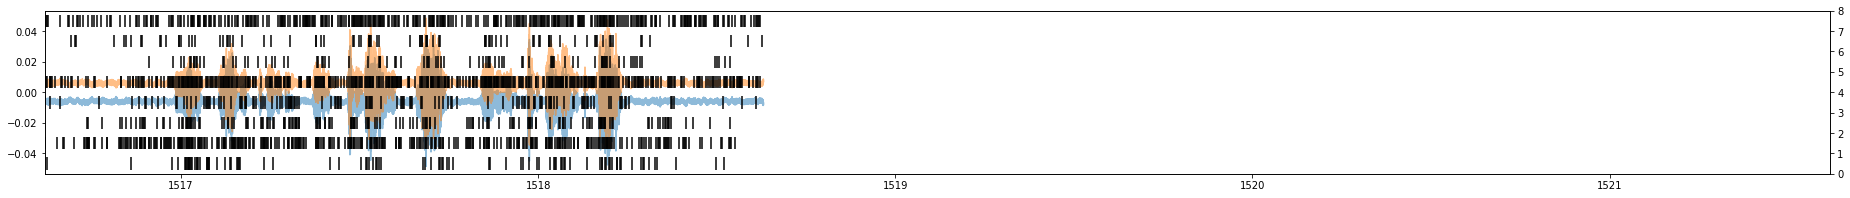

student_song_24
24


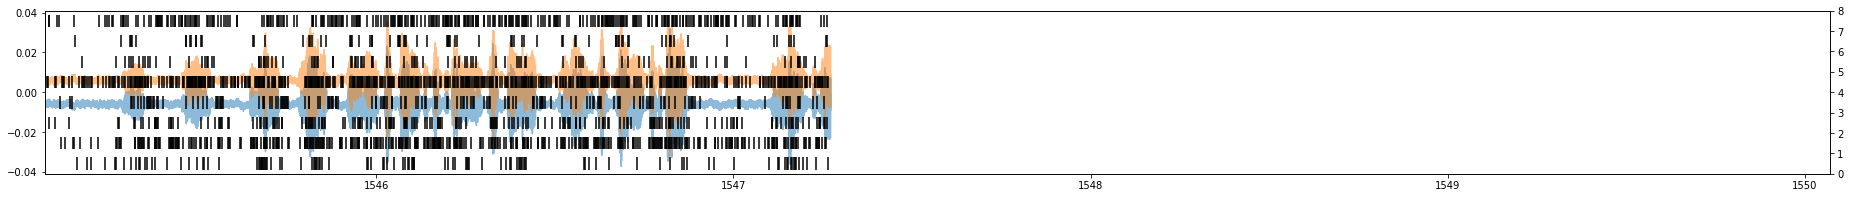

student_song_25
25


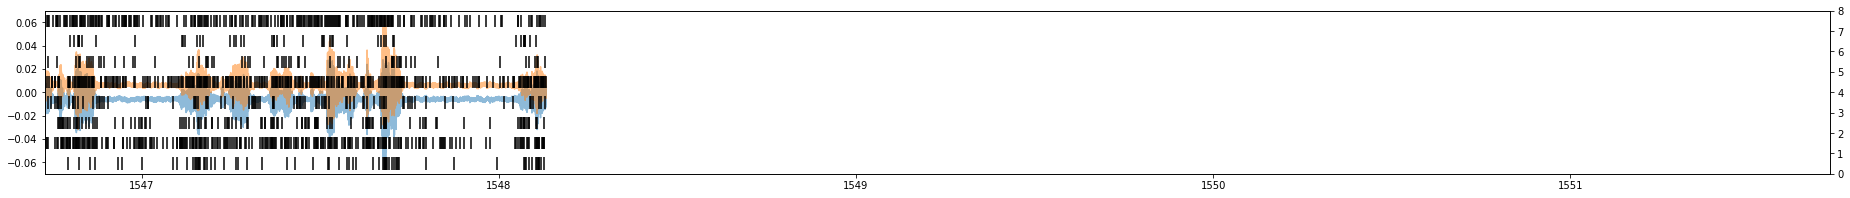

student_song_26
26


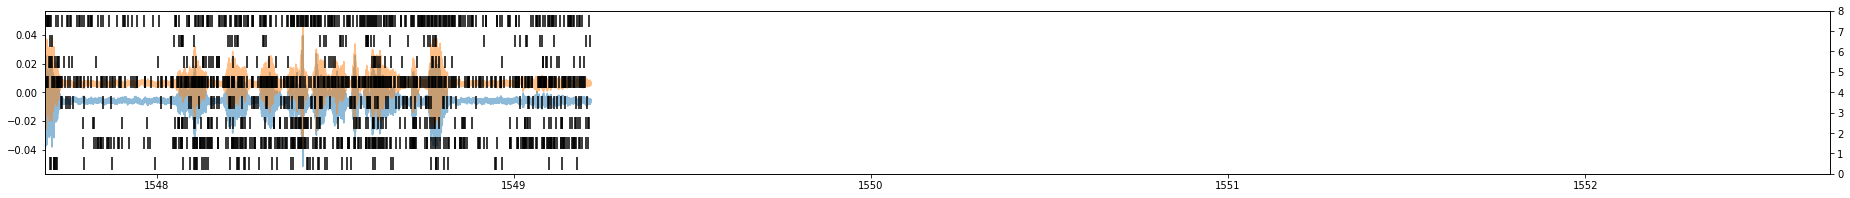

student_song_27
27


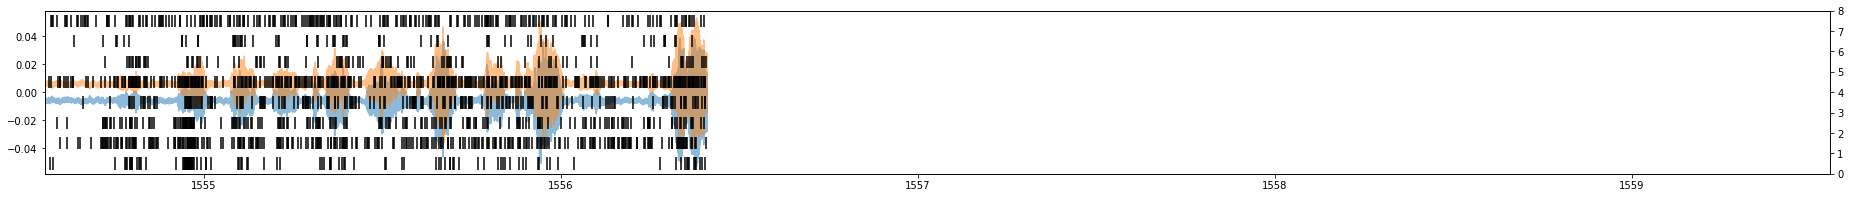

student_song_28
28


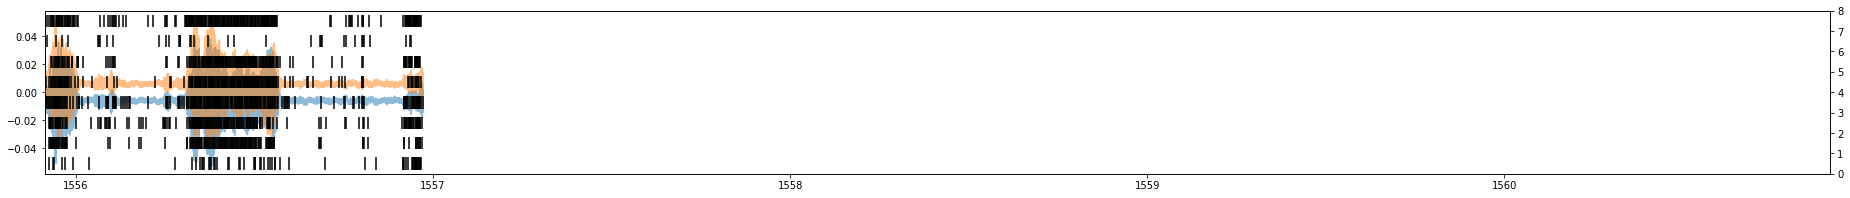

student_song_29
29


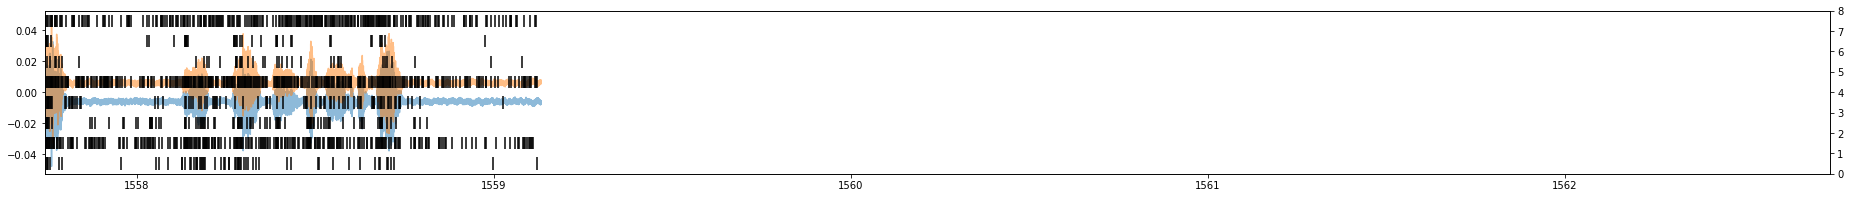

student_song_30
30


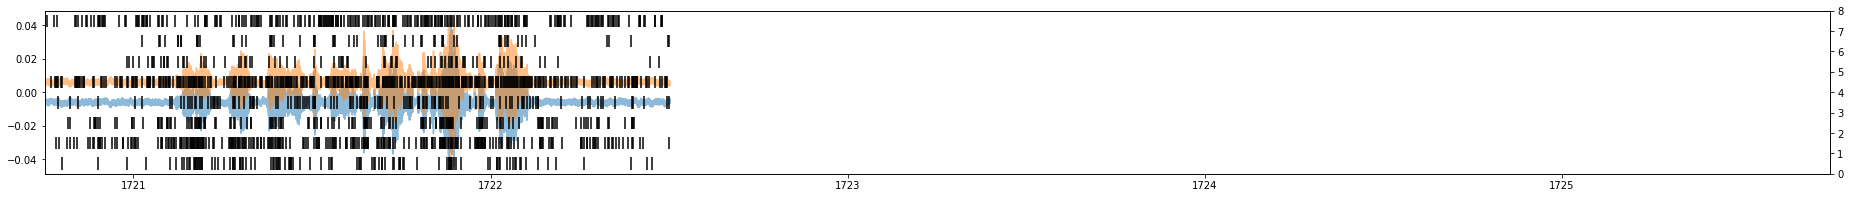

student_song_31
31


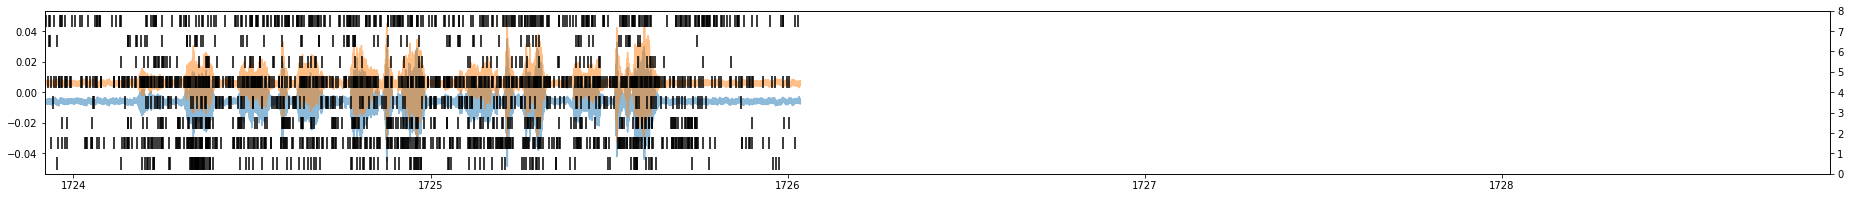

student_song_32
32


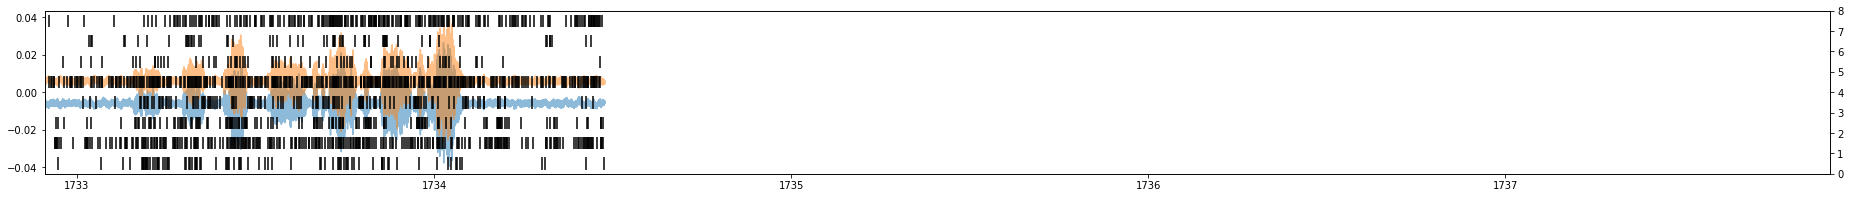

student_song_33
33


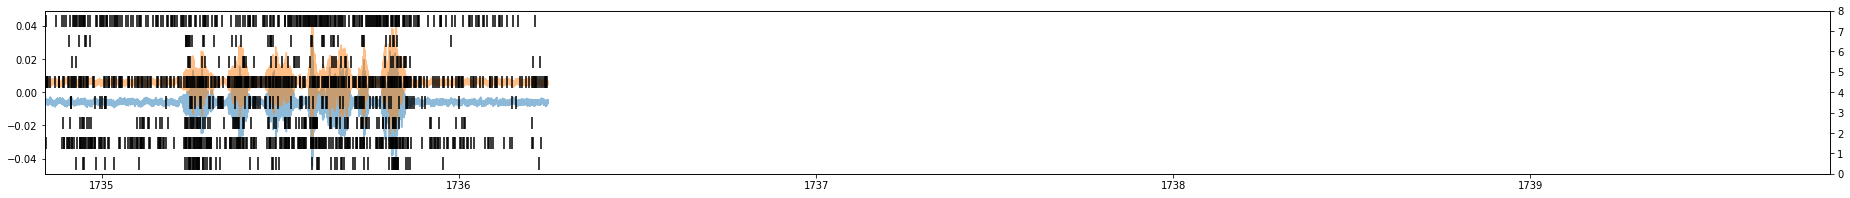

student_song_34
34


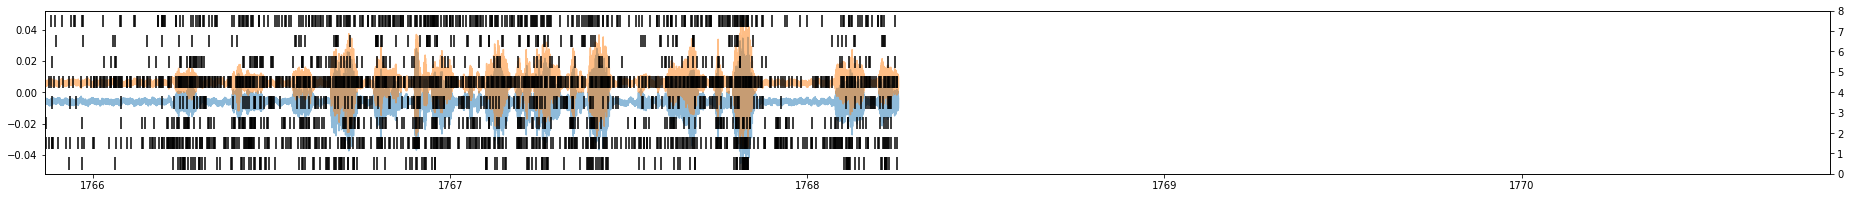

student_song_35
35


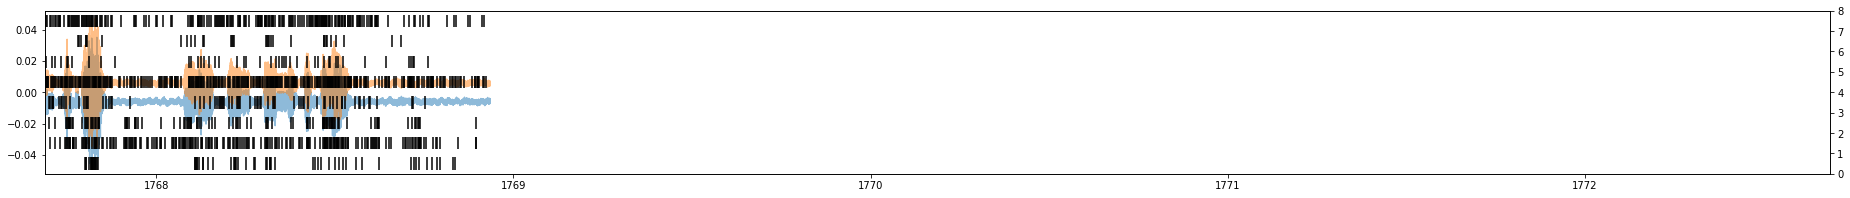

student_song_36
36


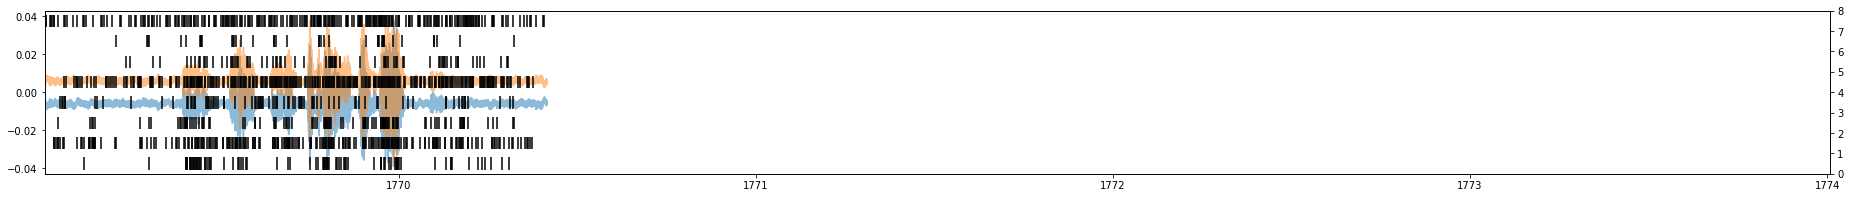

student_song_37
37


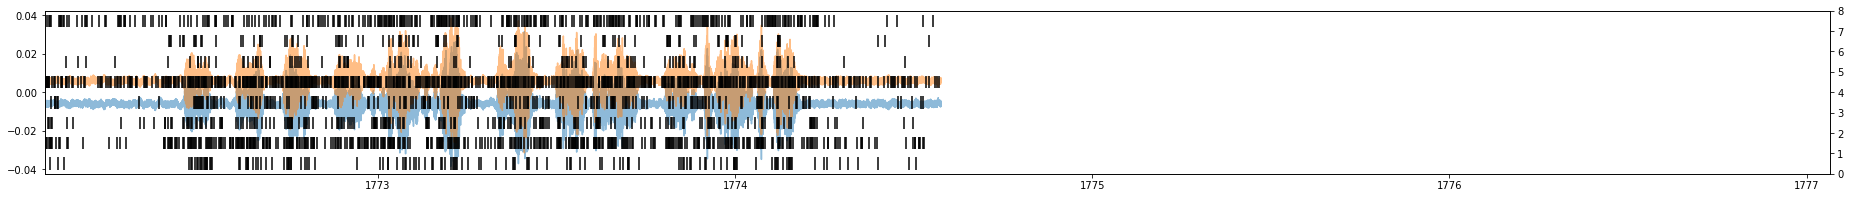

student_song_38
38


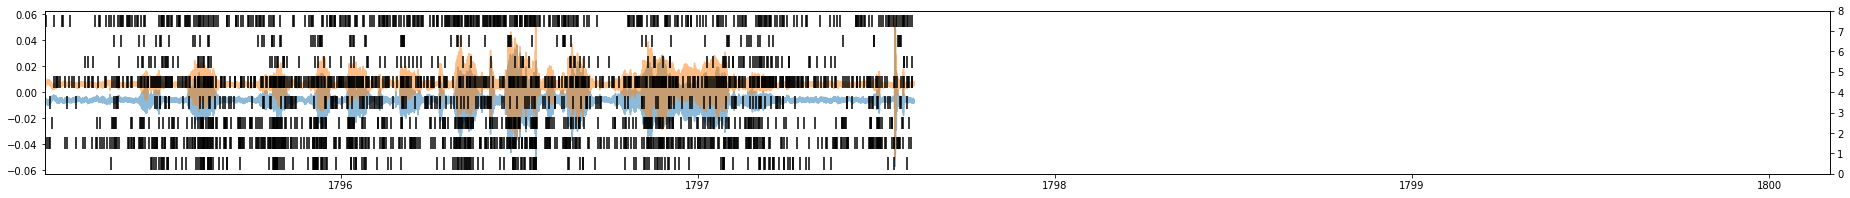

student_song_39
39


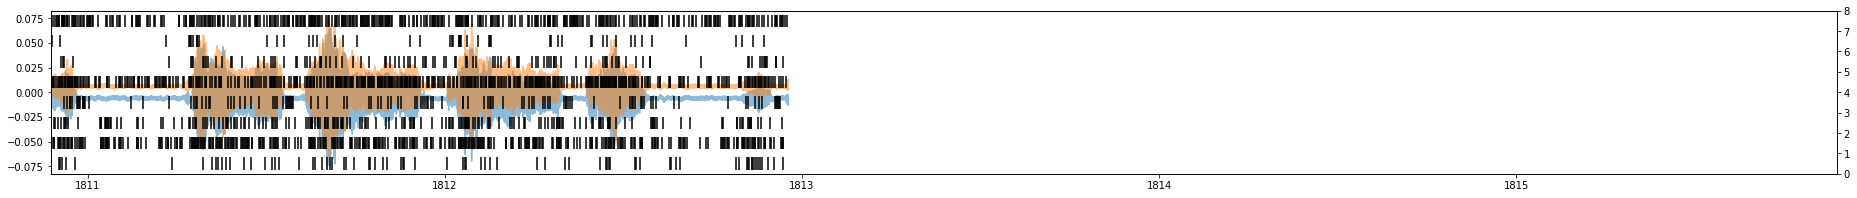

student_song_40
40


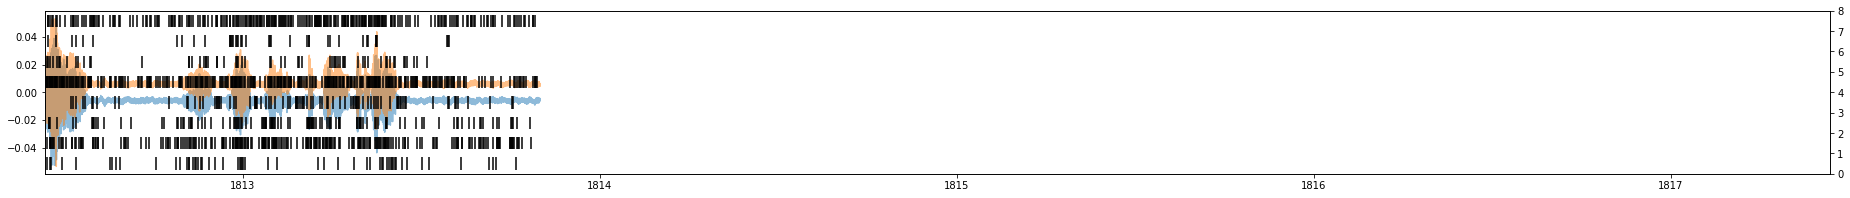

student_song_41
41


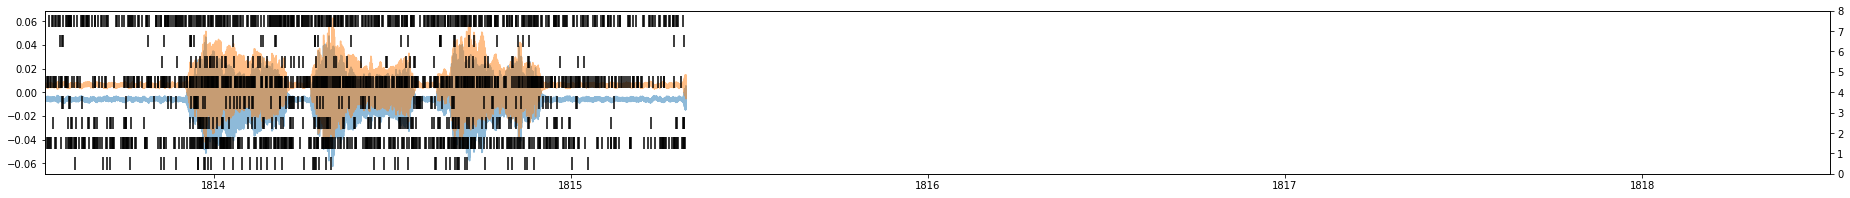

student_song_42
42


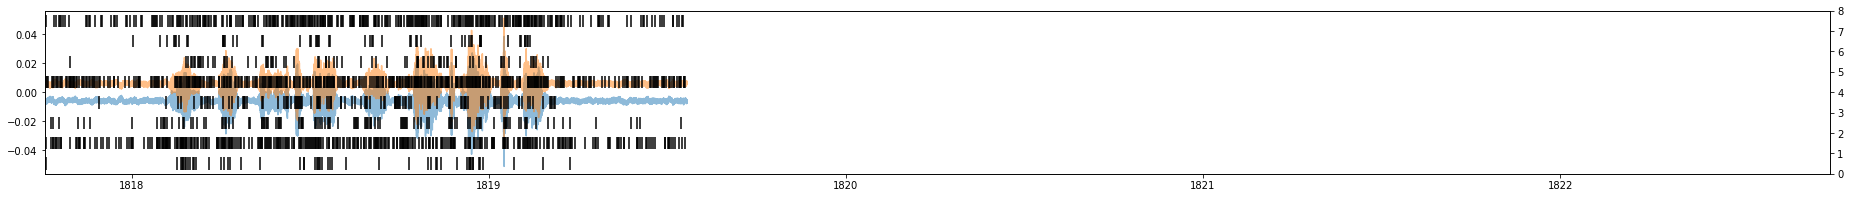

student_song_43
43


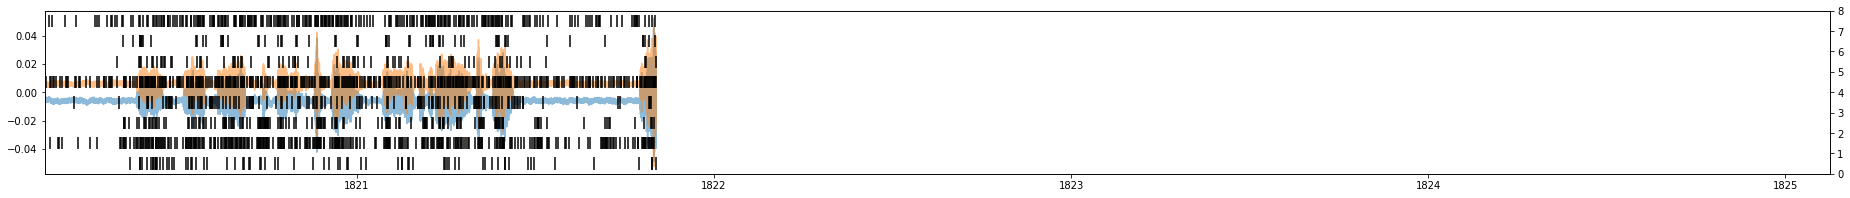

student_song_44
44


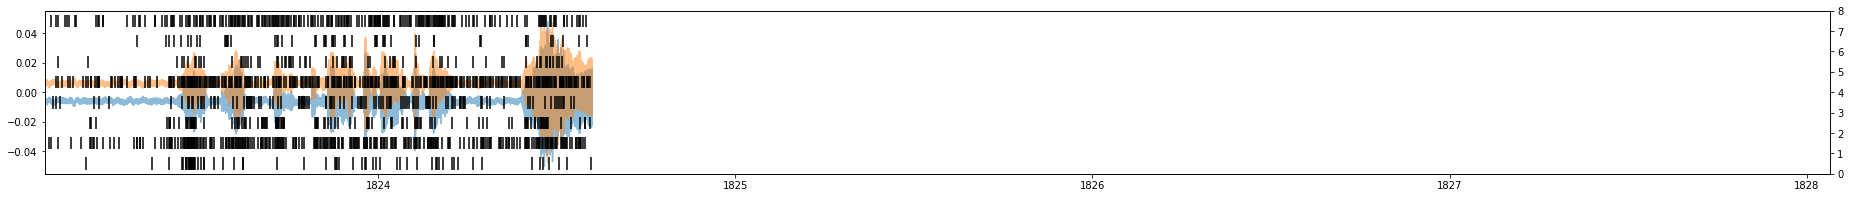

student_song_45
45


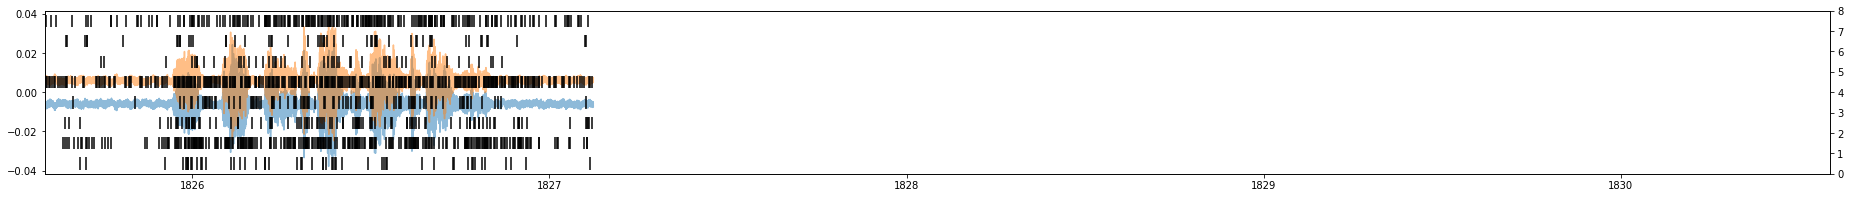

student_song_46
46


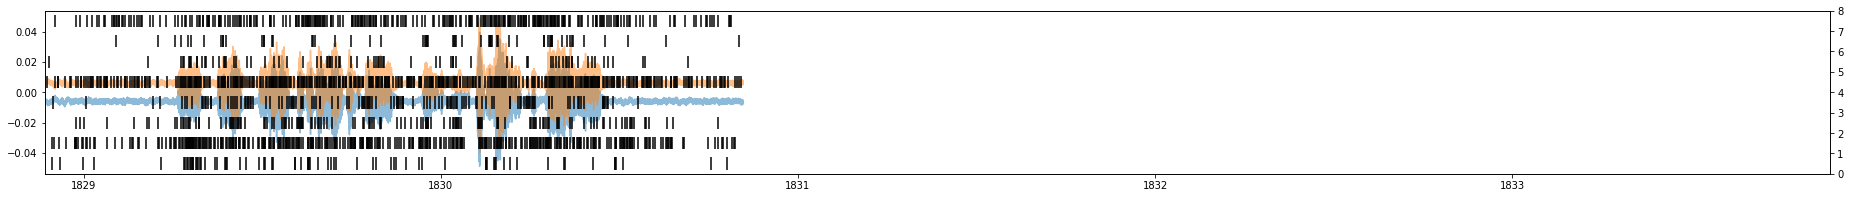

student_song_47
47


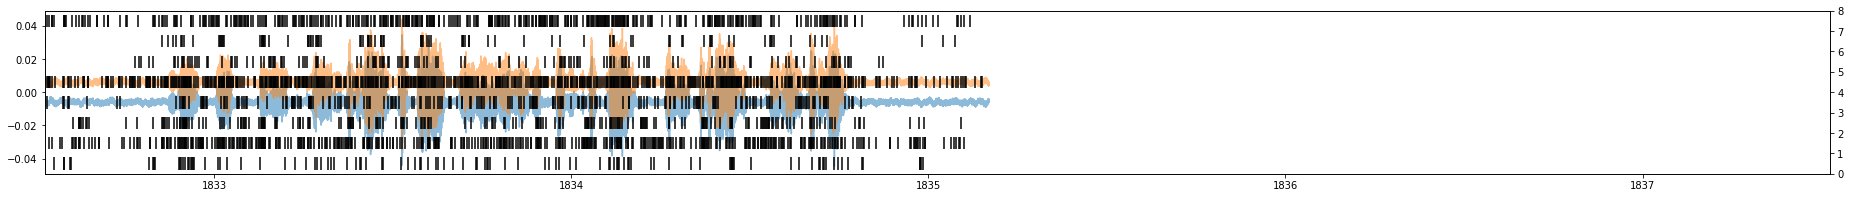

student_song_48
48


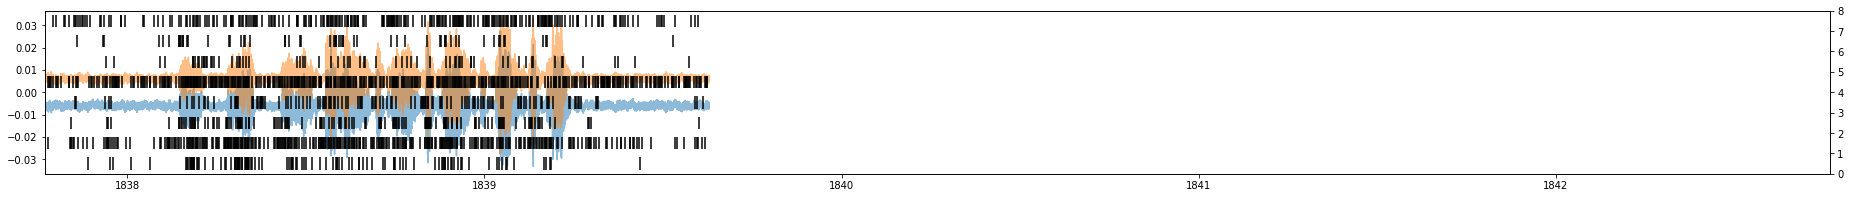

student_song_49
49


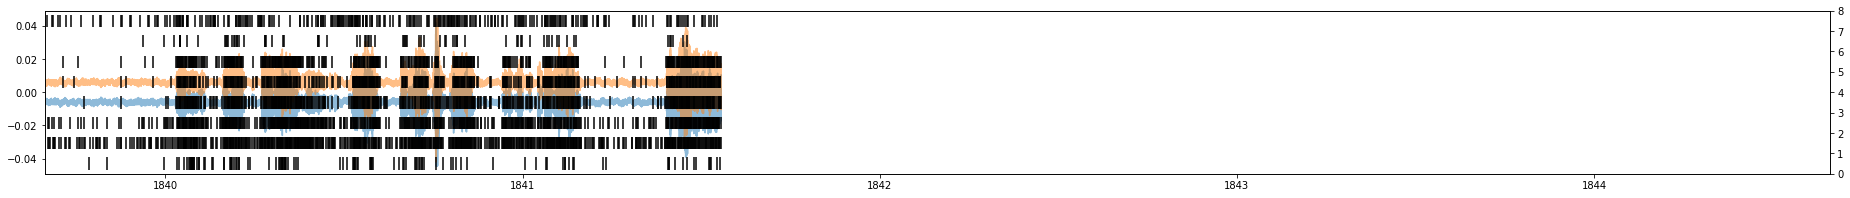

student_song_50
50


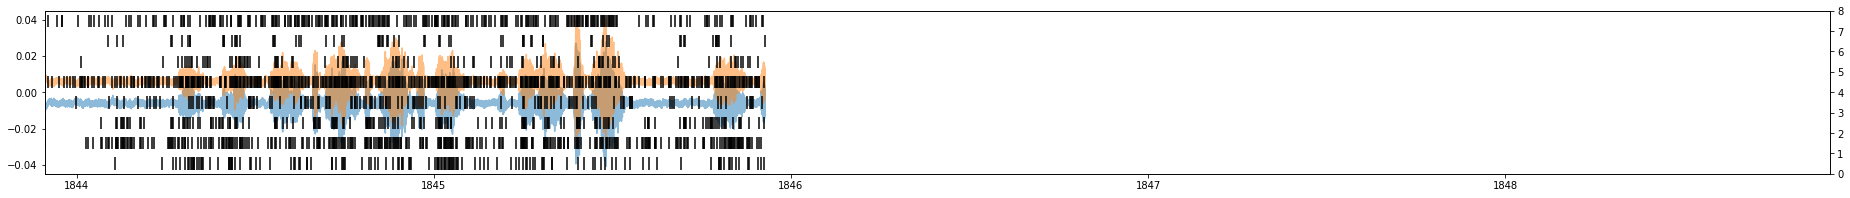

student_song_51
51


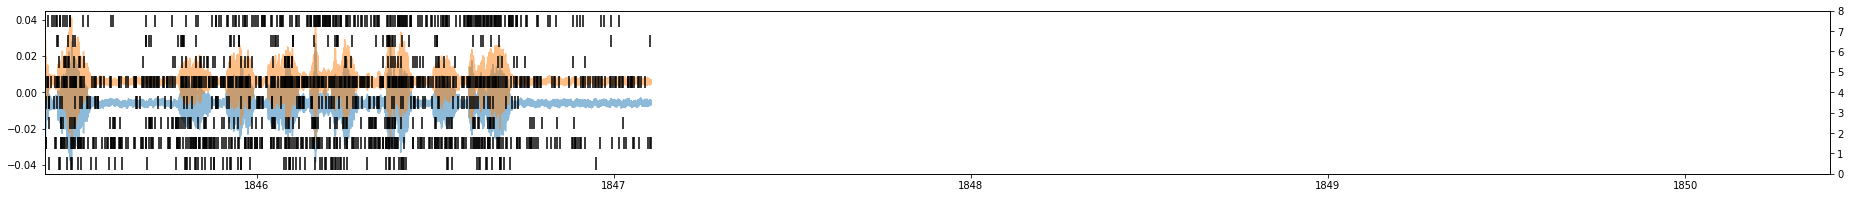

student_song_52
52


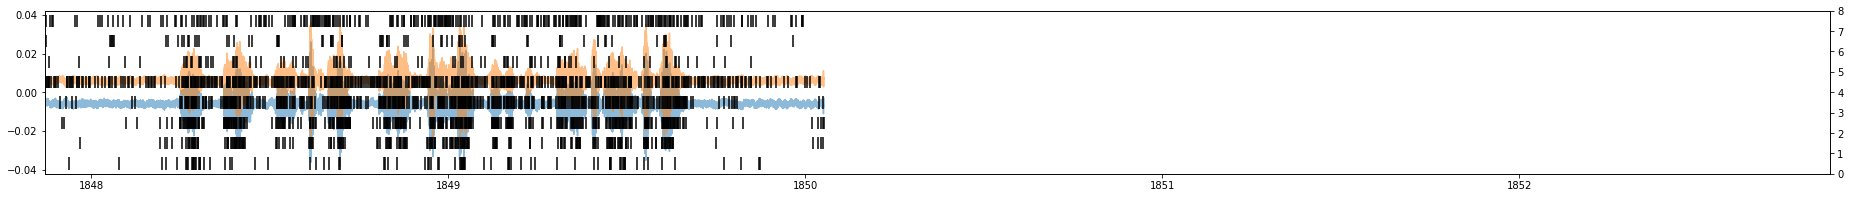

student_song_53
53


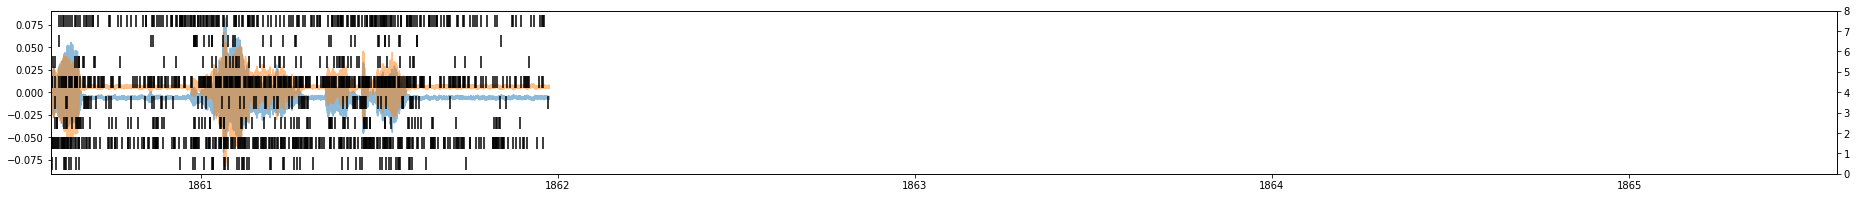

student_song_54
54


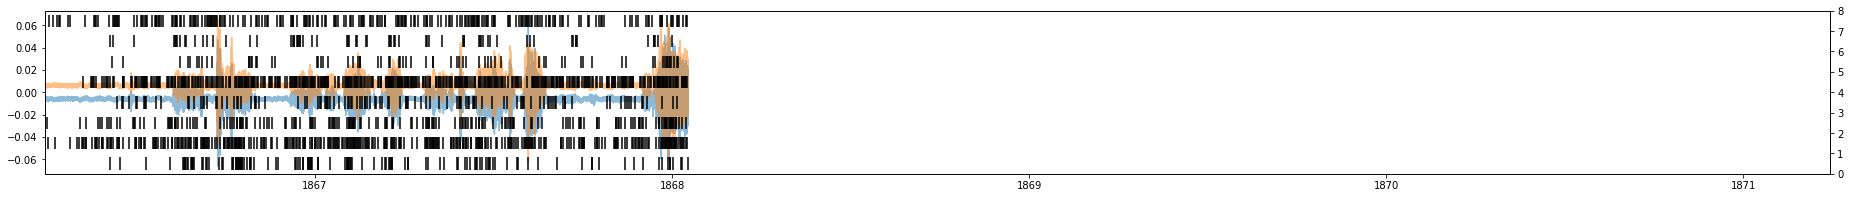

student_song_55
55


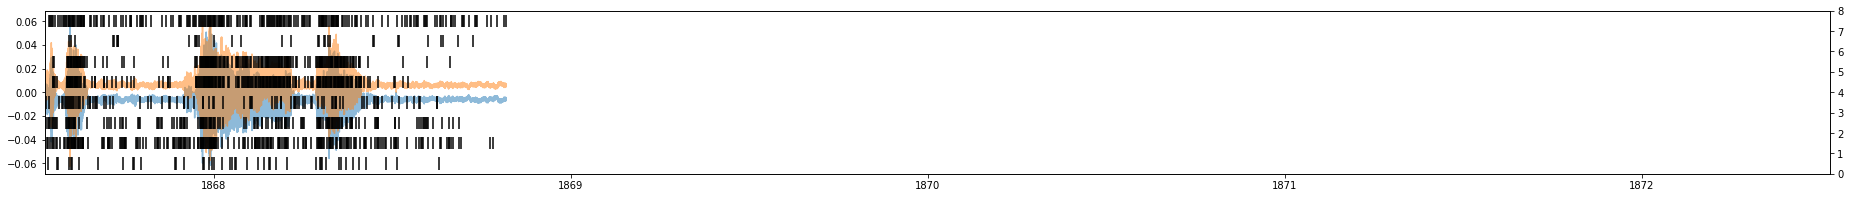

student_song_56
56


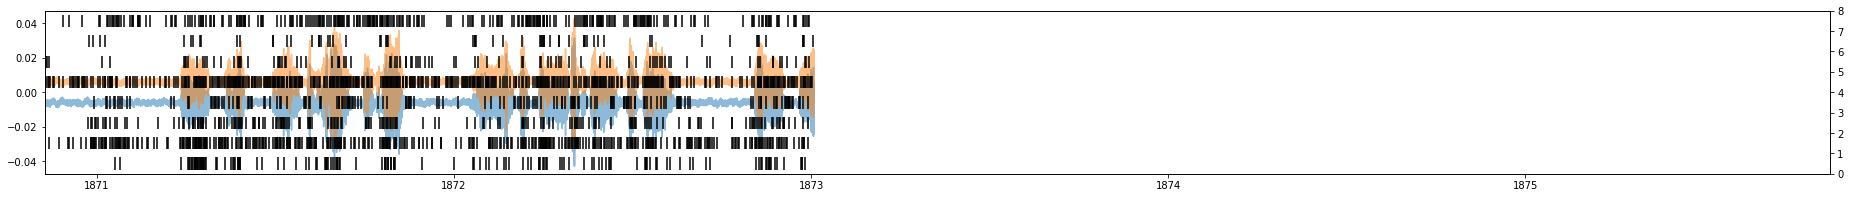

student_song_57
57


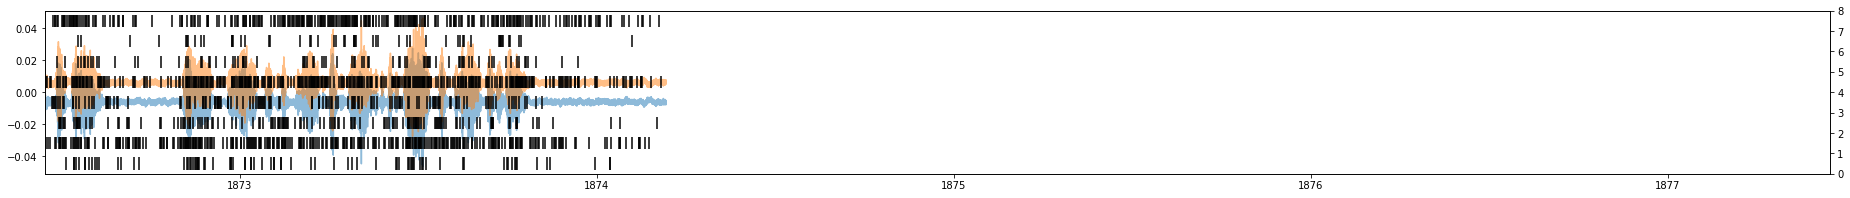

student_song_58
58


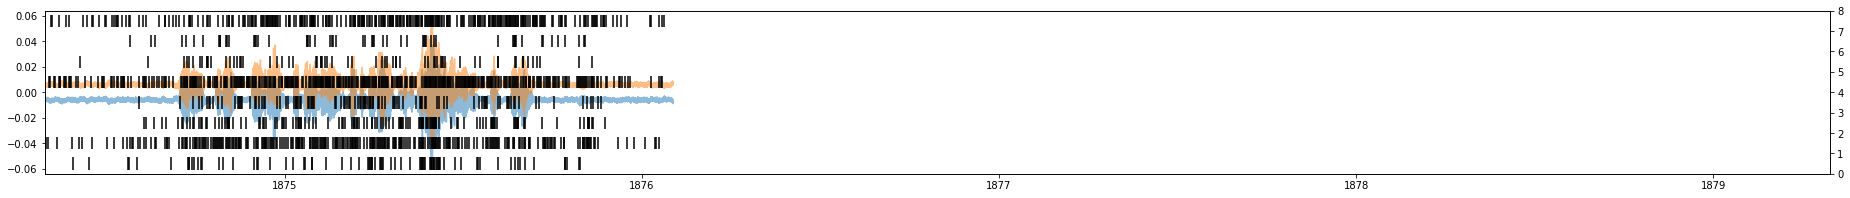

student_song_59
59


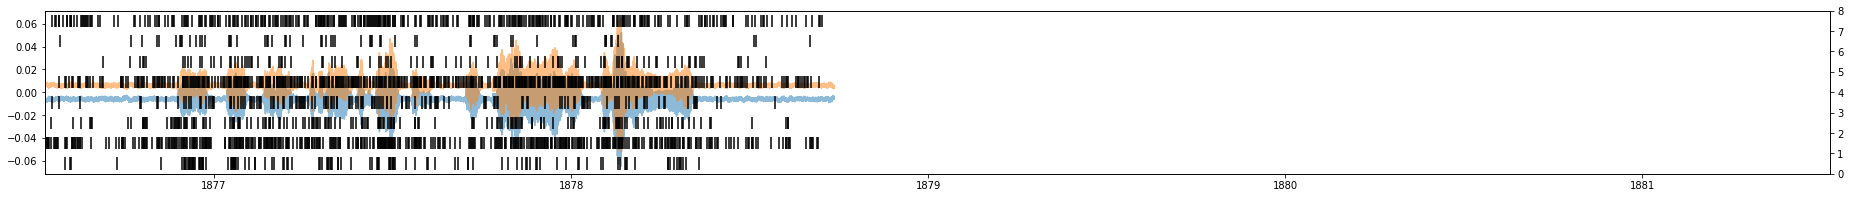

student_song_60
60


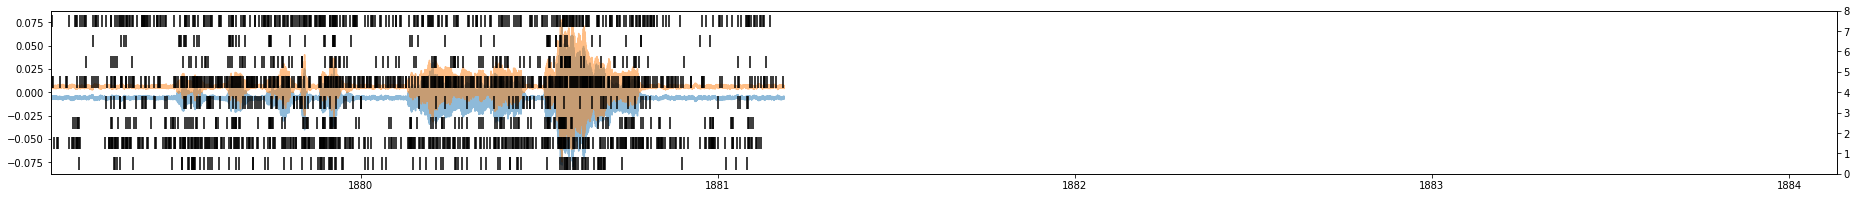

student_song_61
61


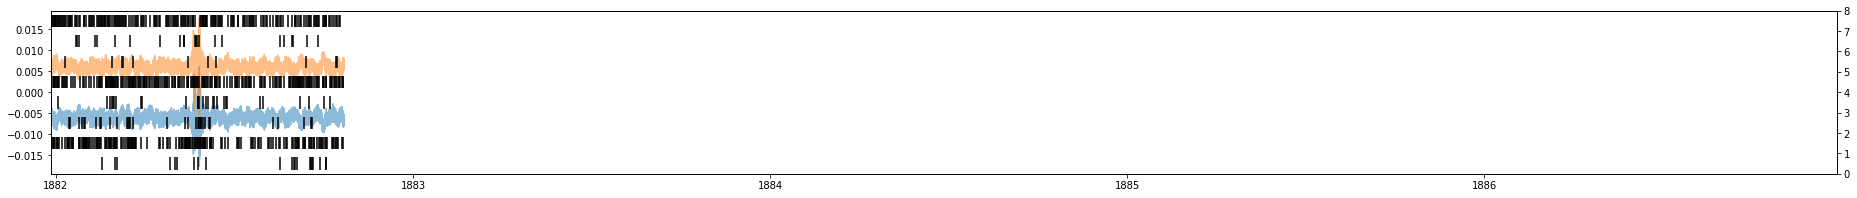

student_song_62
62


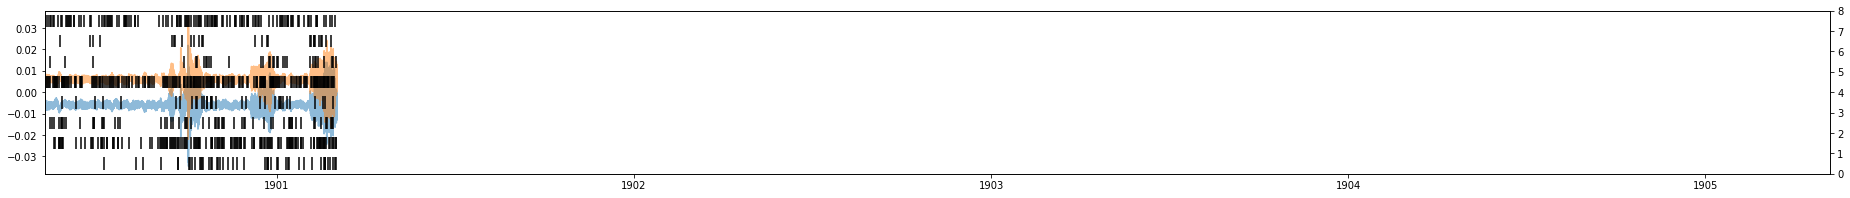

student_song_63
63


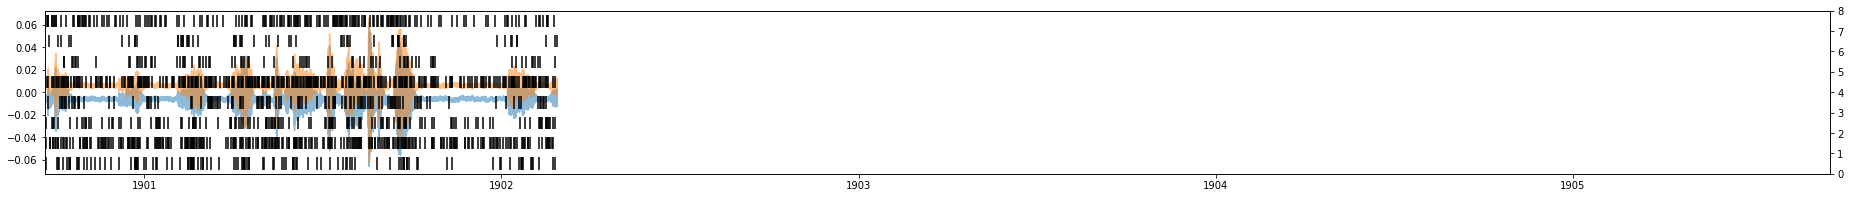

student_song_64
64


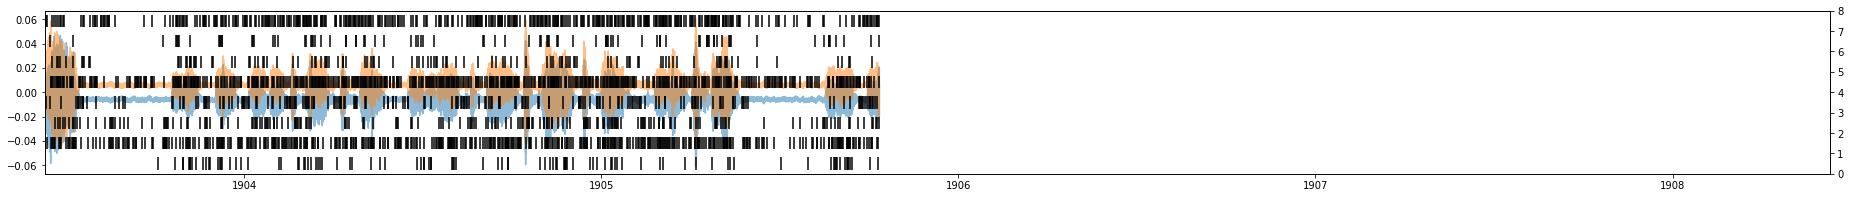

student_song_65
65


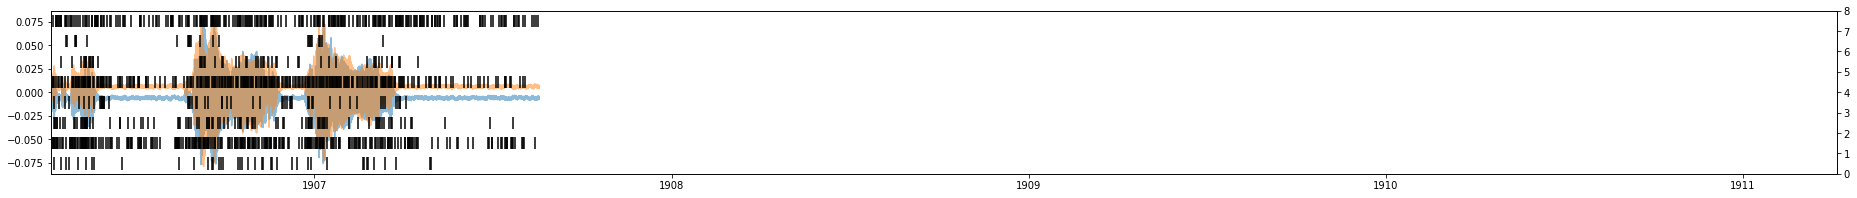

student_song_66
66


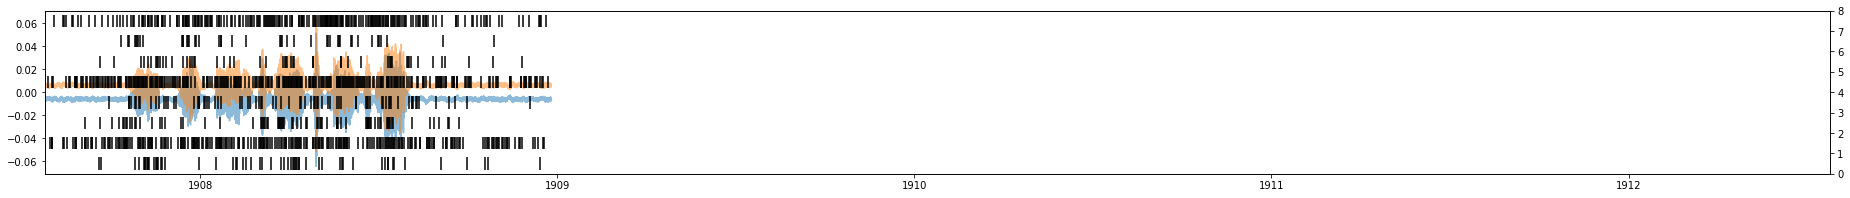

student_song_67
67


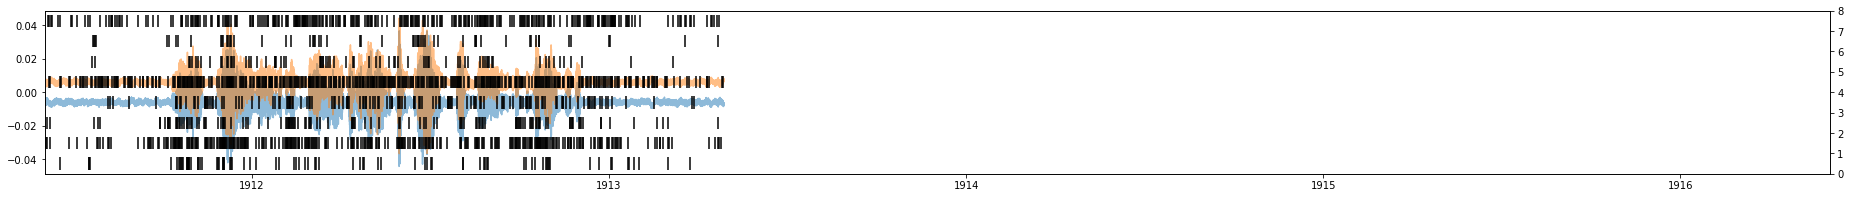

student_song_68
68


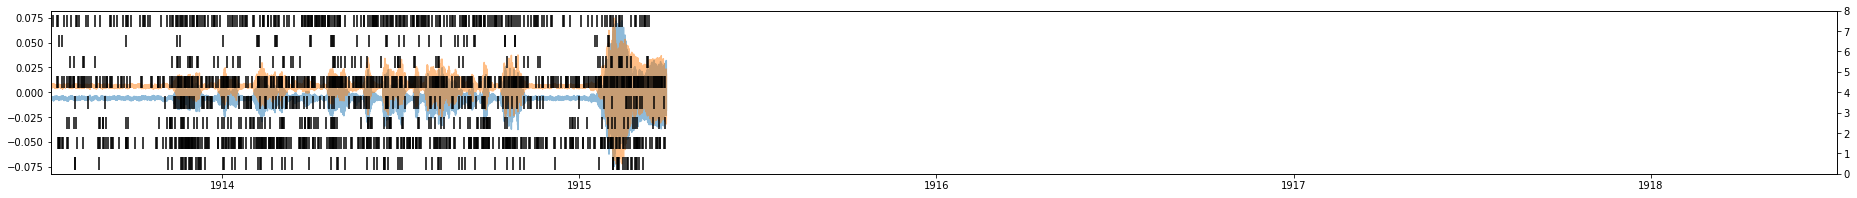

student_song_69
69


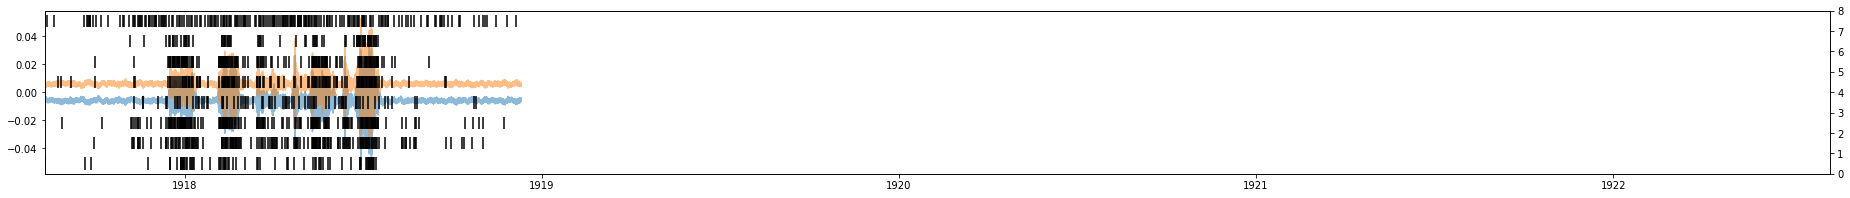

student_song_70
70


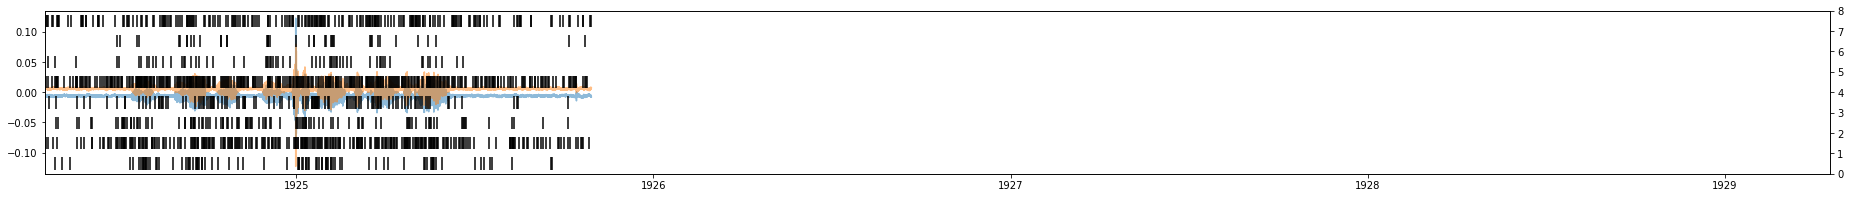

student_song_71
71


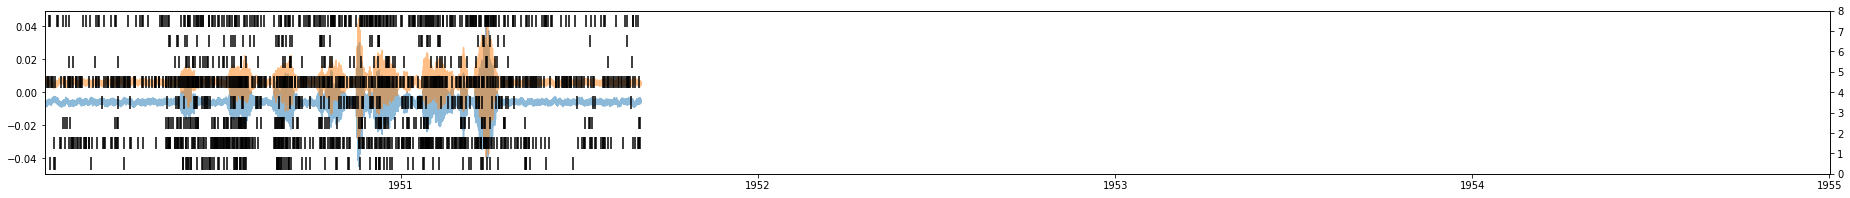

student_song_72
72


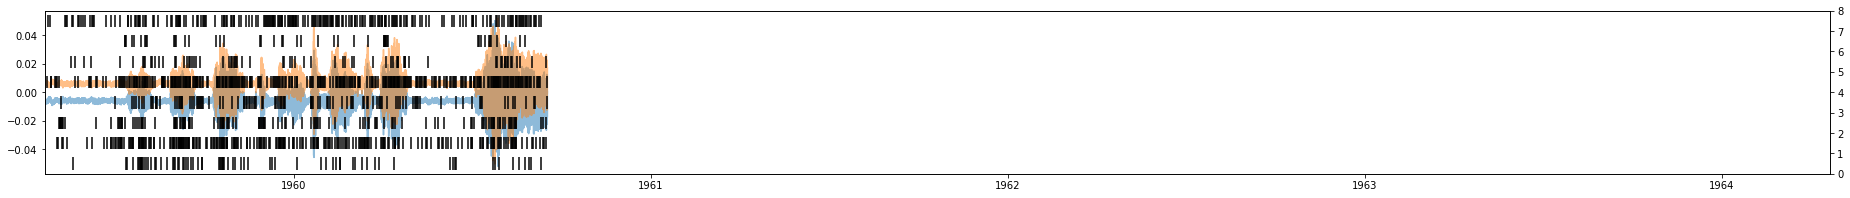

student_song_73
73


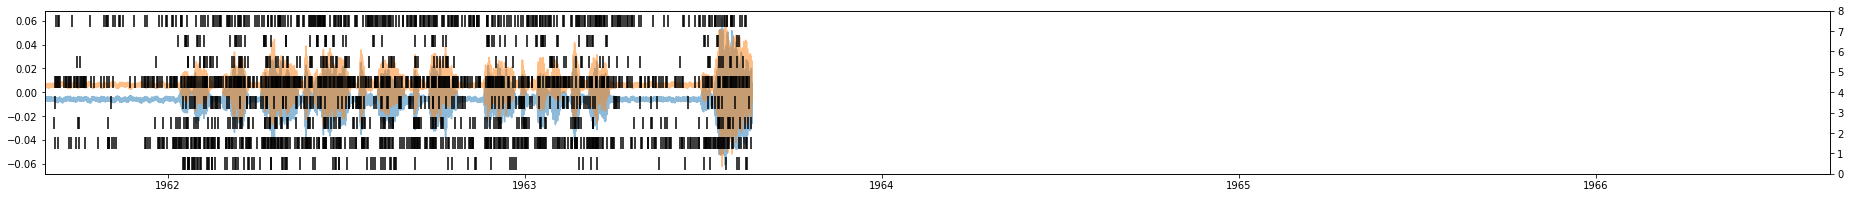

student_song_74
74


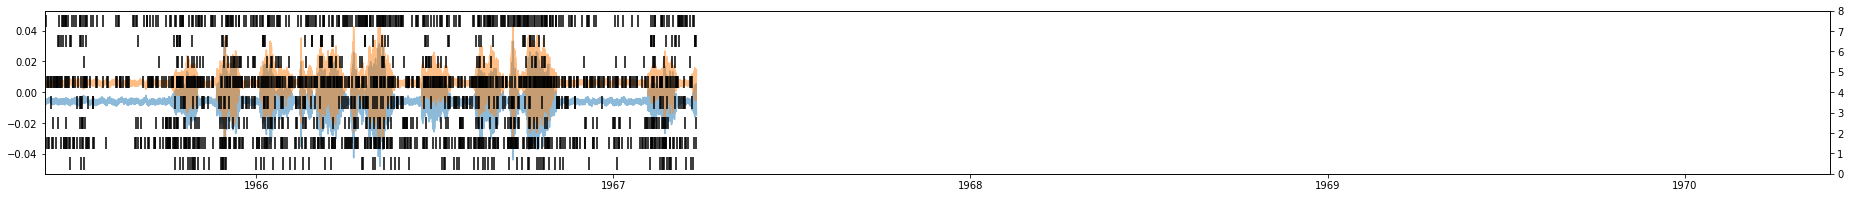

student_song_75
75


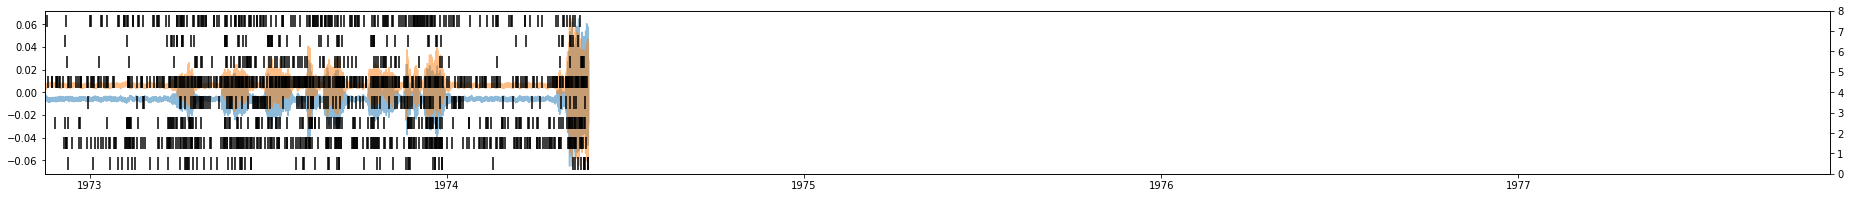

student_song_76
76


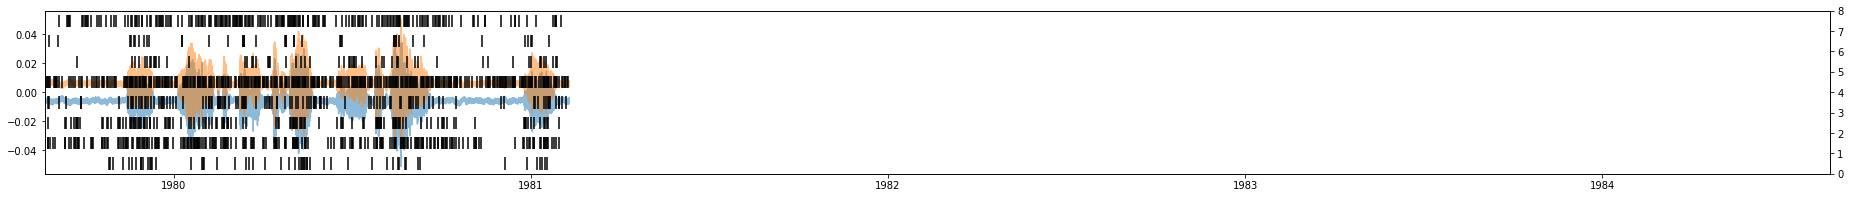

student_song_77
77


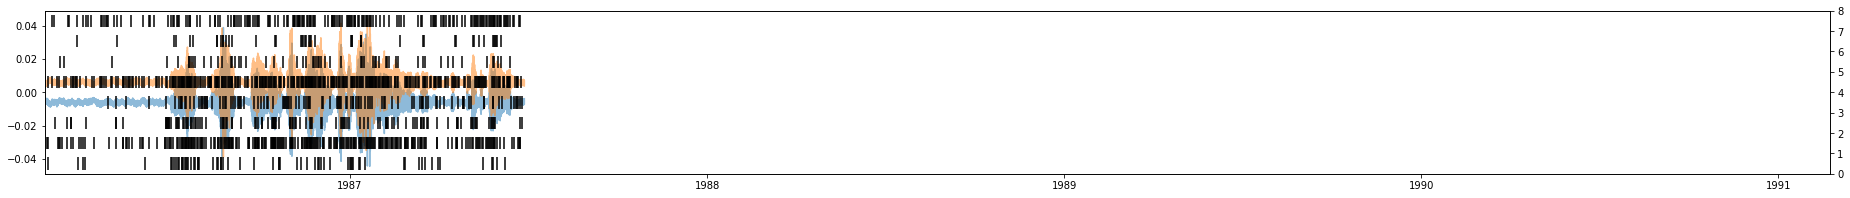

student_song_78
78


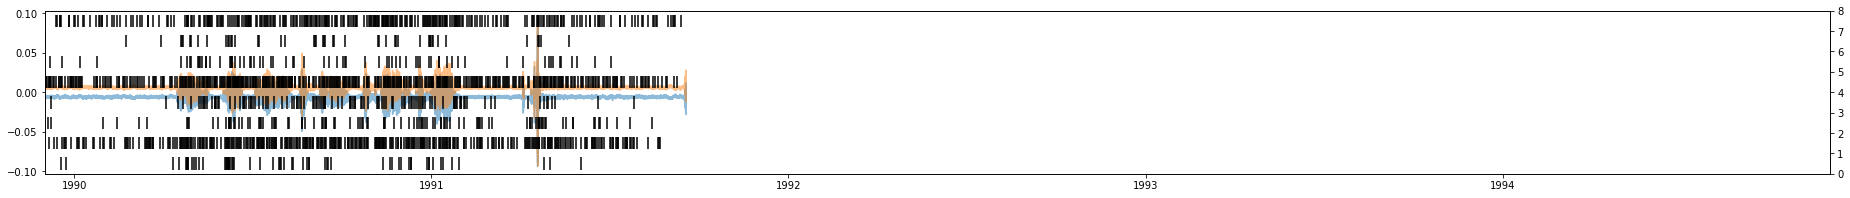

student_song_79
79


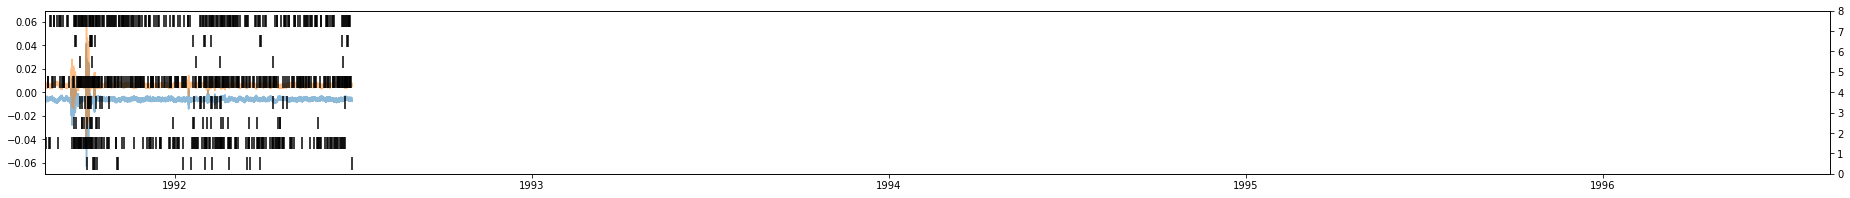

student_song_80
80


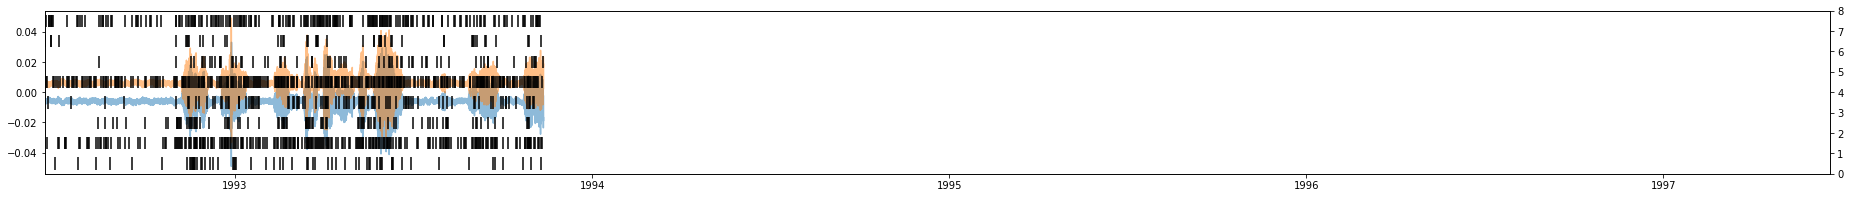

student_song_81
81


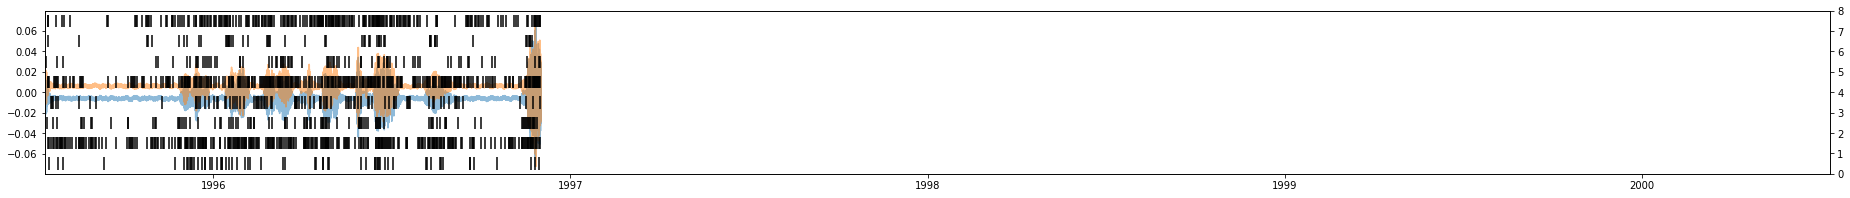

student_song_82
82


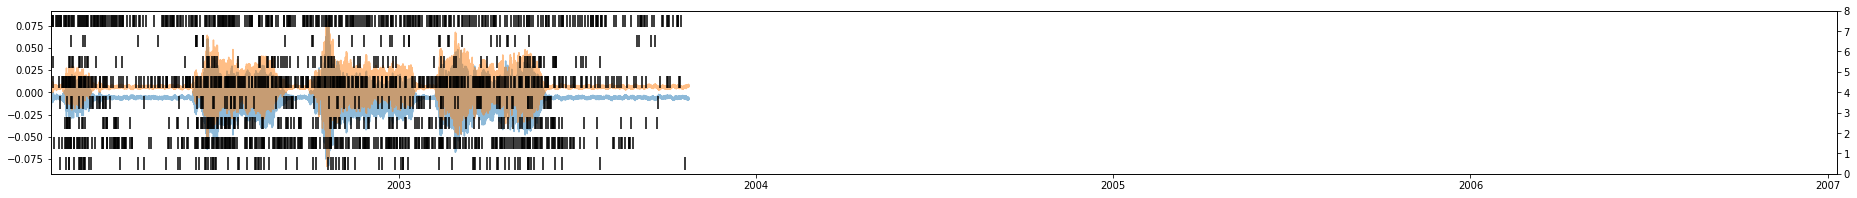

student_song_83
83


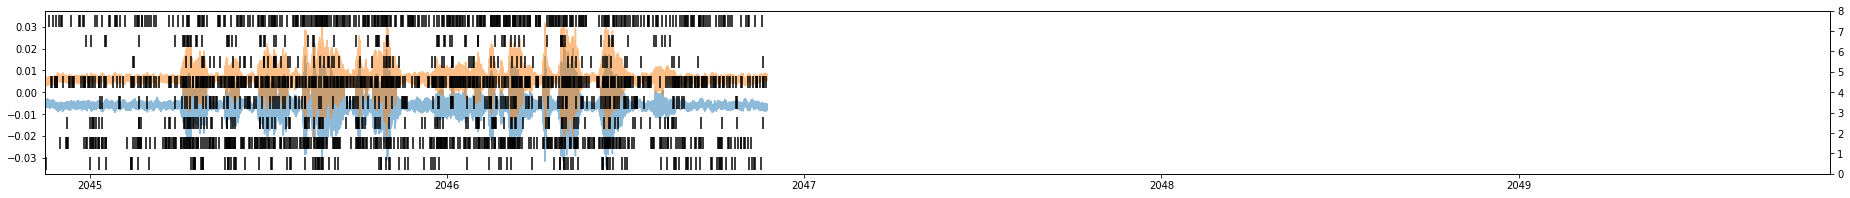

student_song_84
84


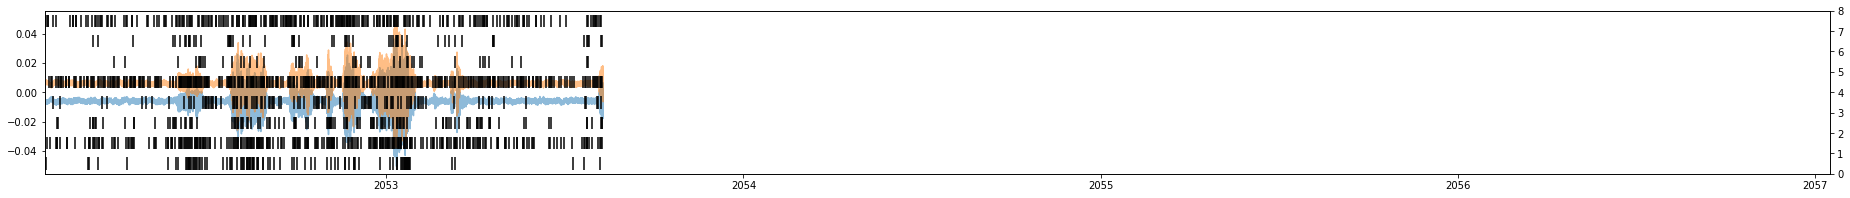

student_song_85
85


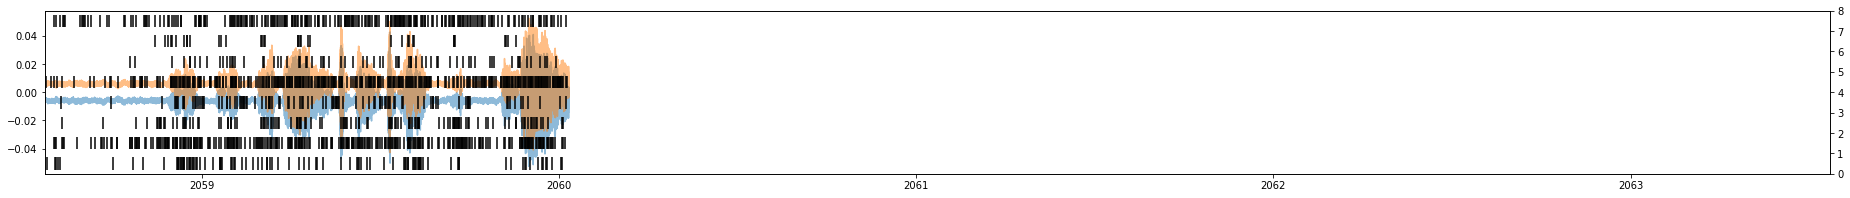

student_song_86
86


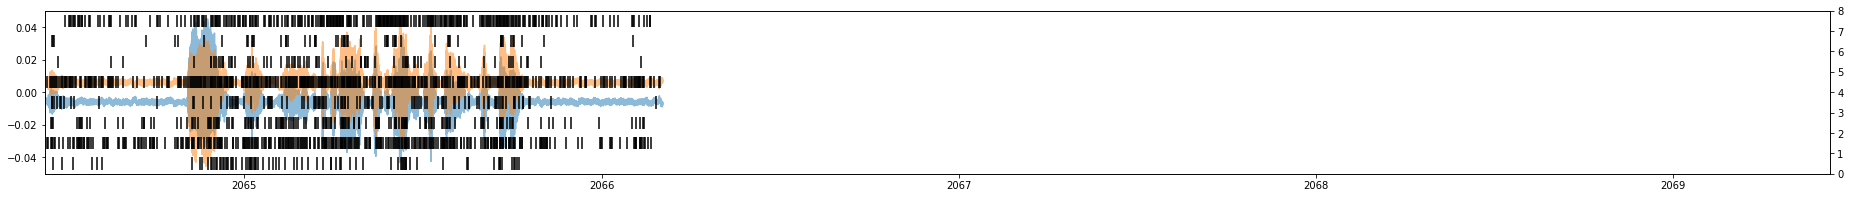

student_song_87
87


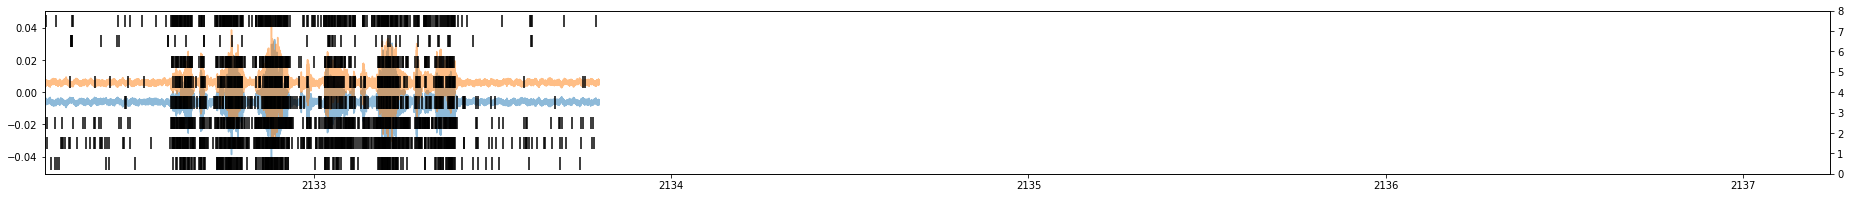

student_song_88
88


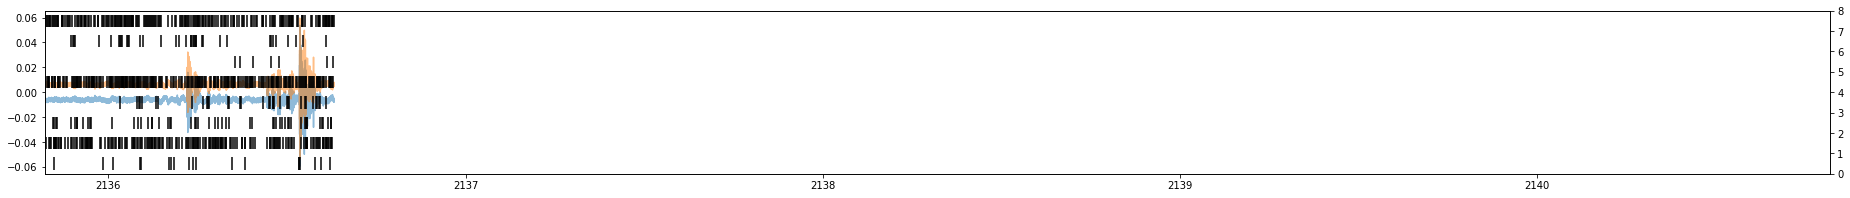

student_song_89
89


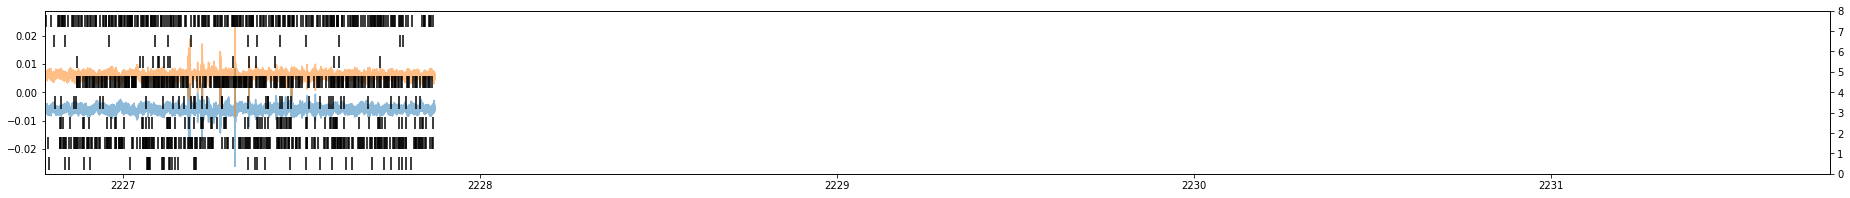

student_song_90
90


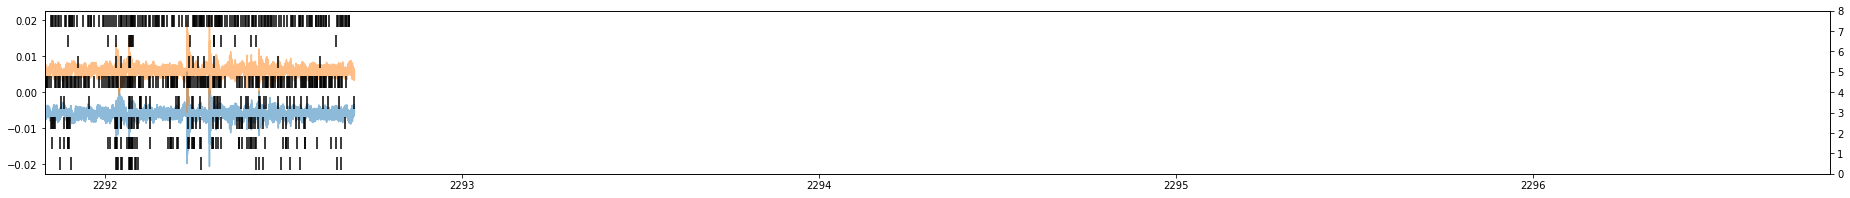

student_song_91
91


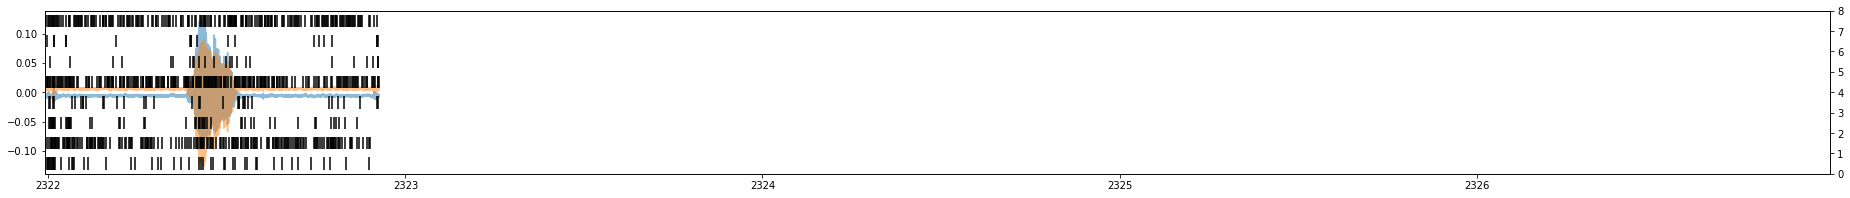

student_song_92
92


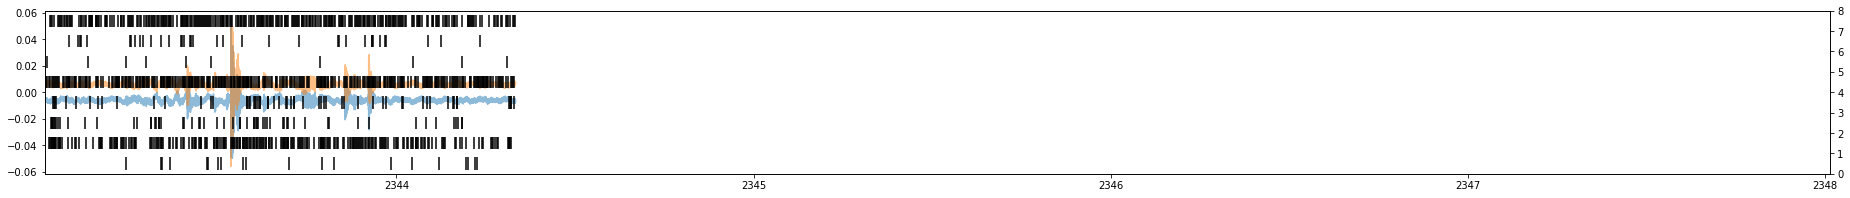

student_song_93
93


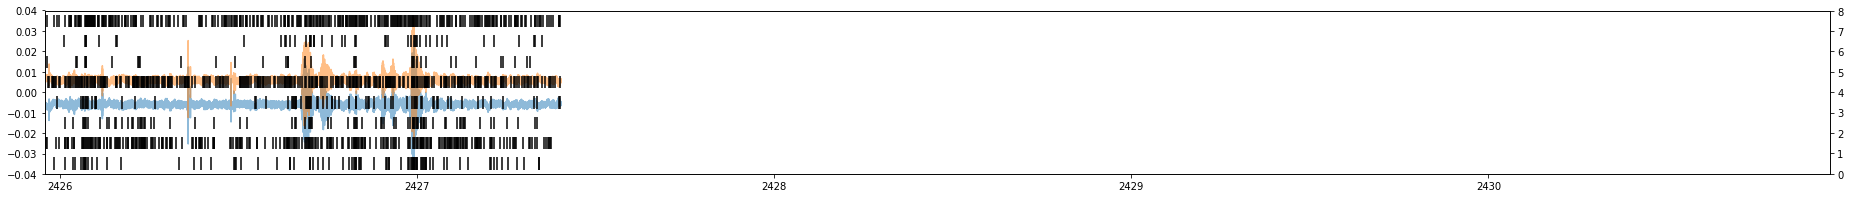

student_song_94
94


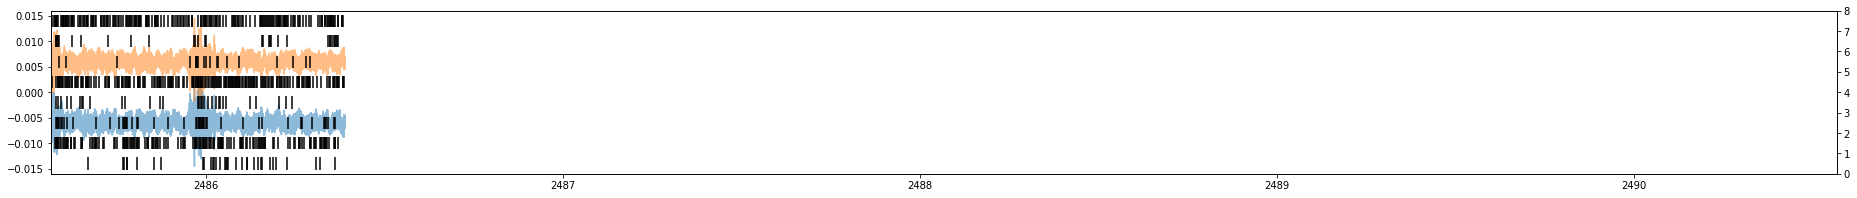

student_song_95
95


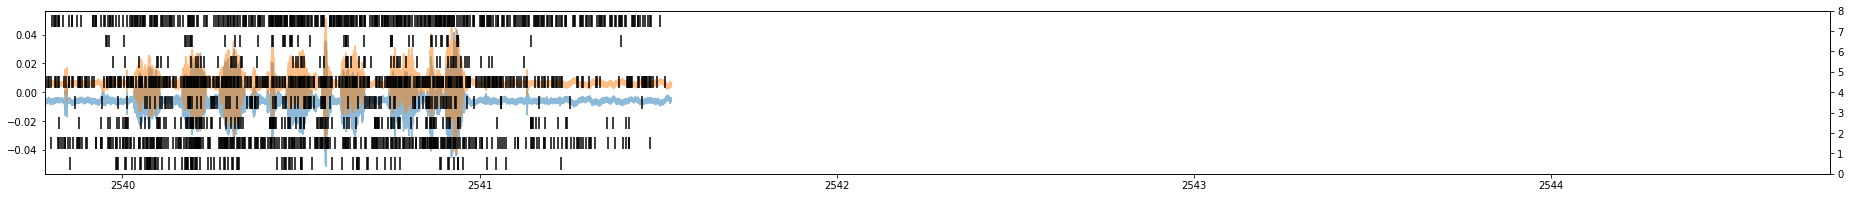

student_song_96
96


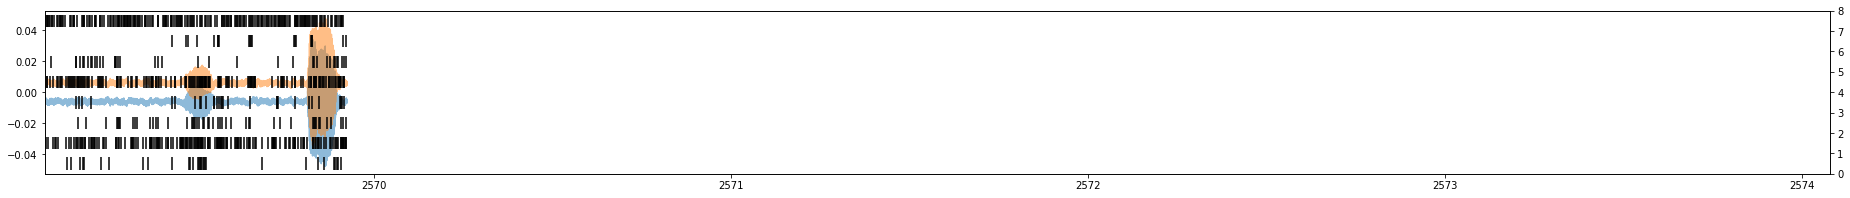

student_song_97
97


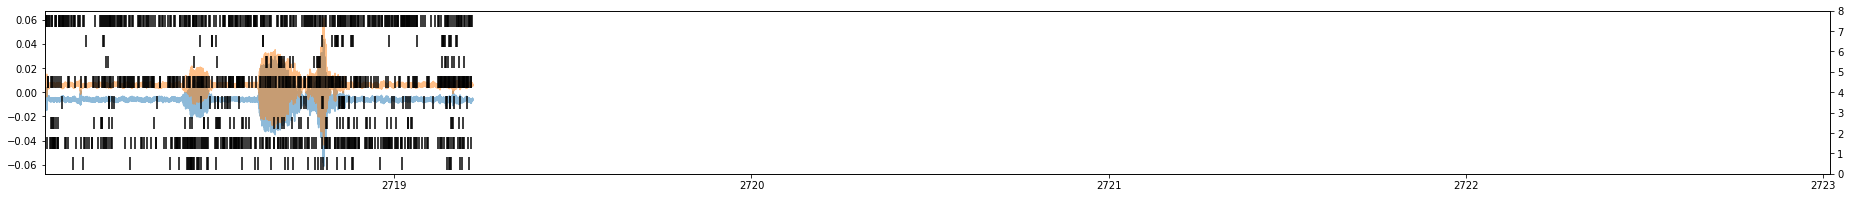

student_song_98
98


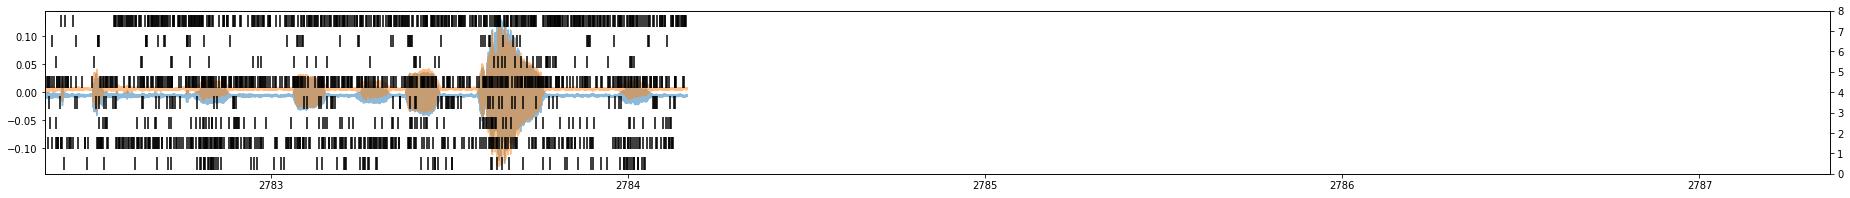

student_song_99
99


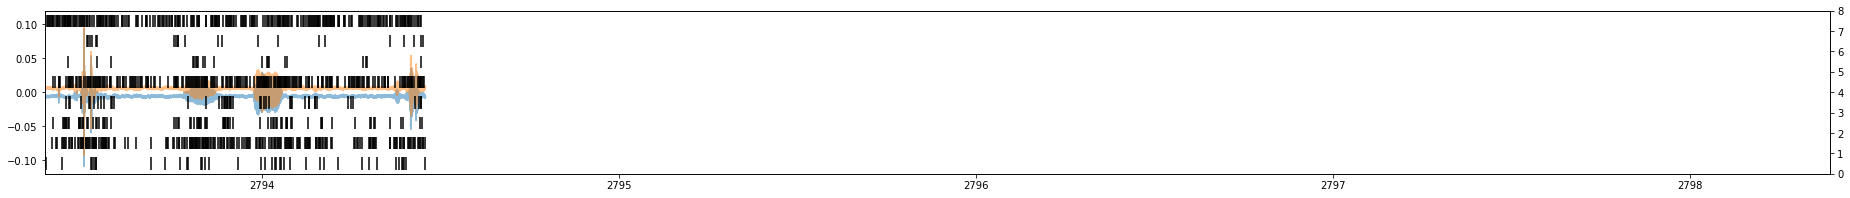

student_song_100
100


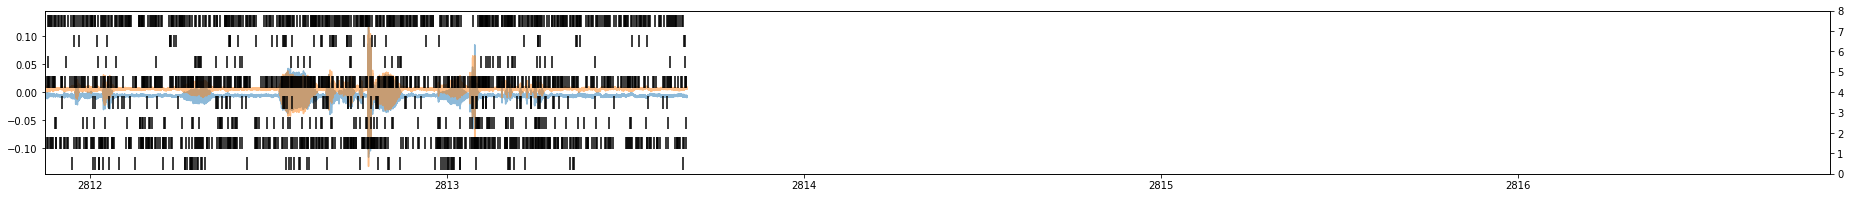

student_song_101
101


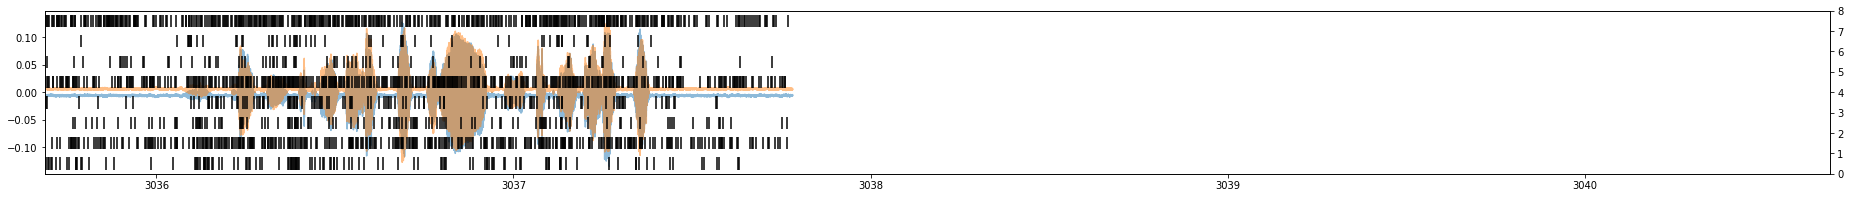

student_song_102
102


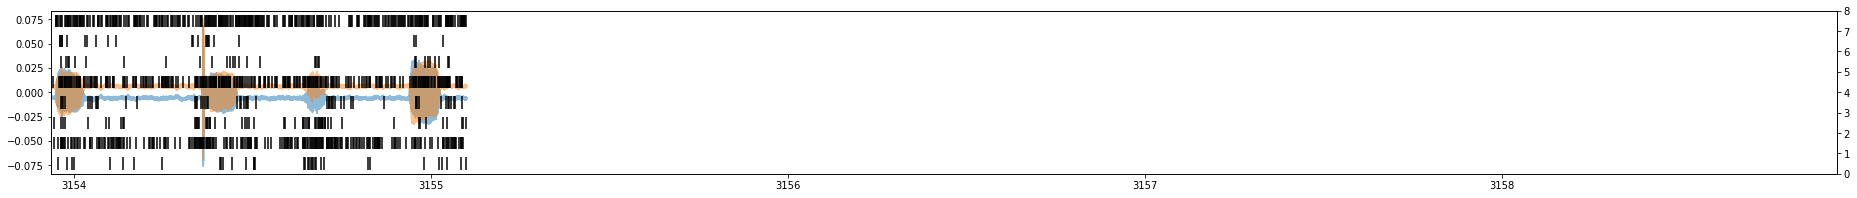

student_song_103
103


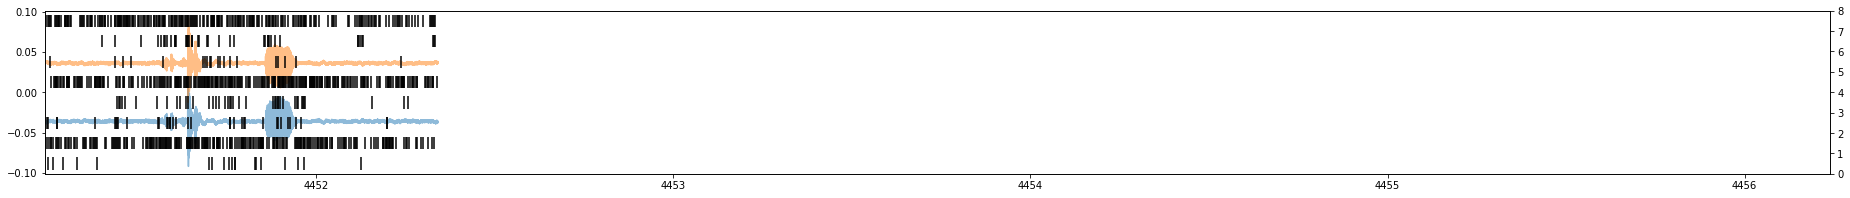

student_song_104
104


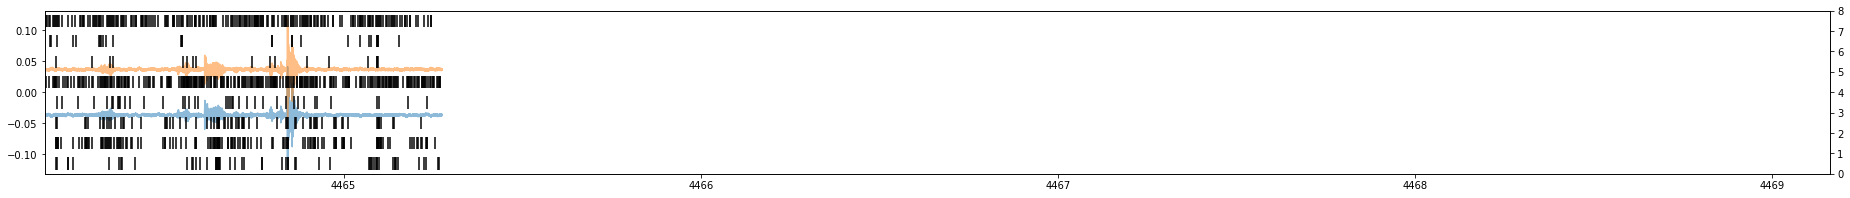

student_song_105
105


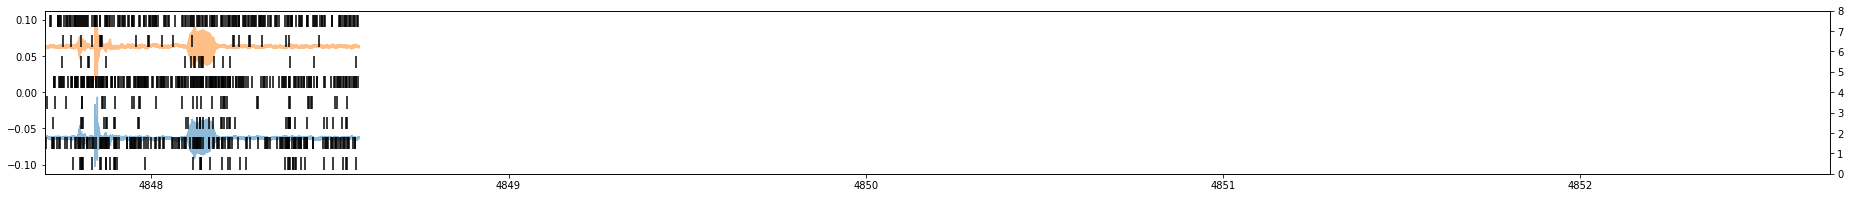

student_song_106
106


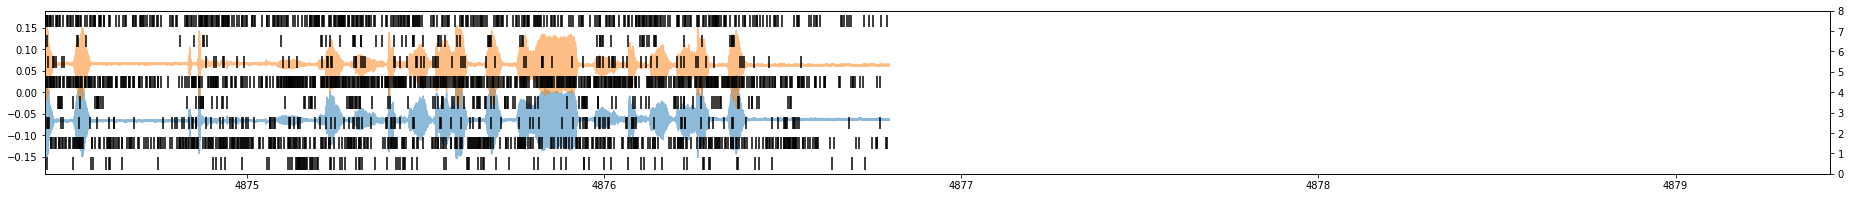

student_song_107
107


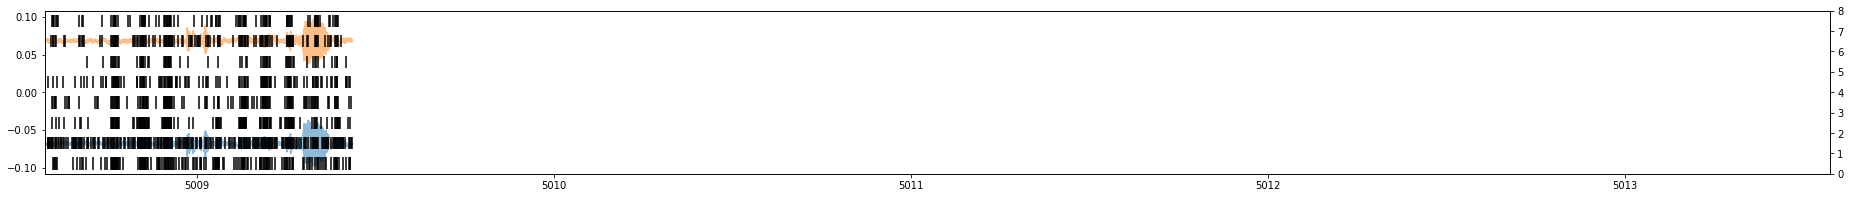

student_song_108
108


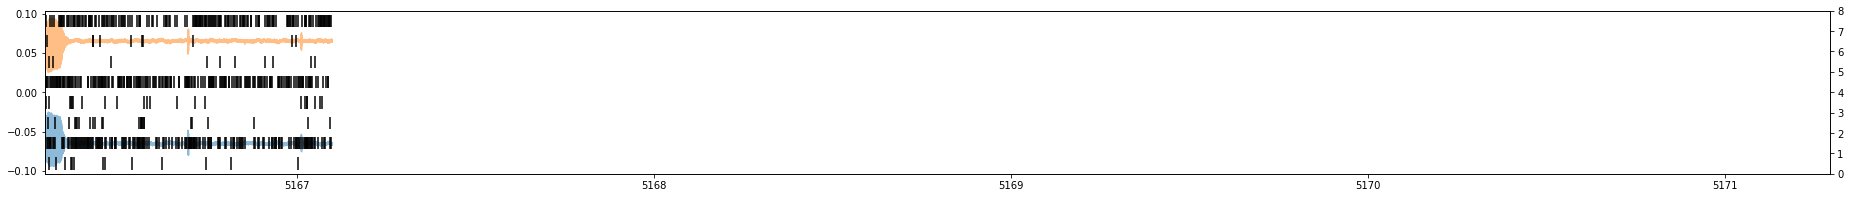

student_song_109
109


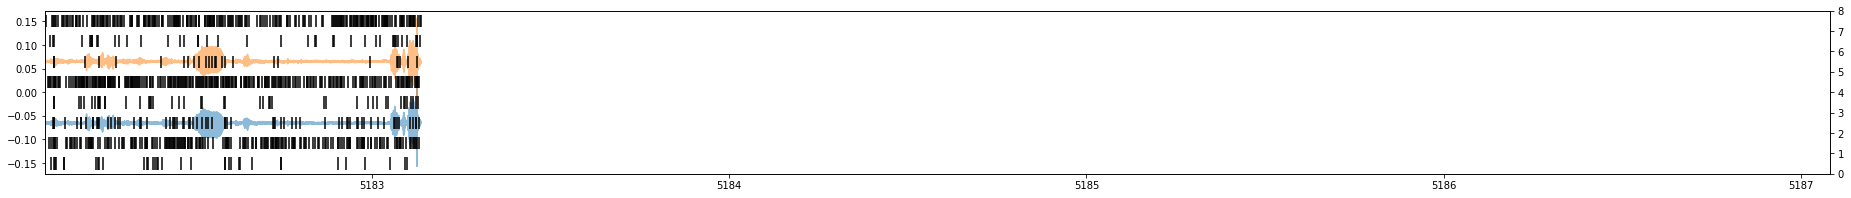

student_song_110
110


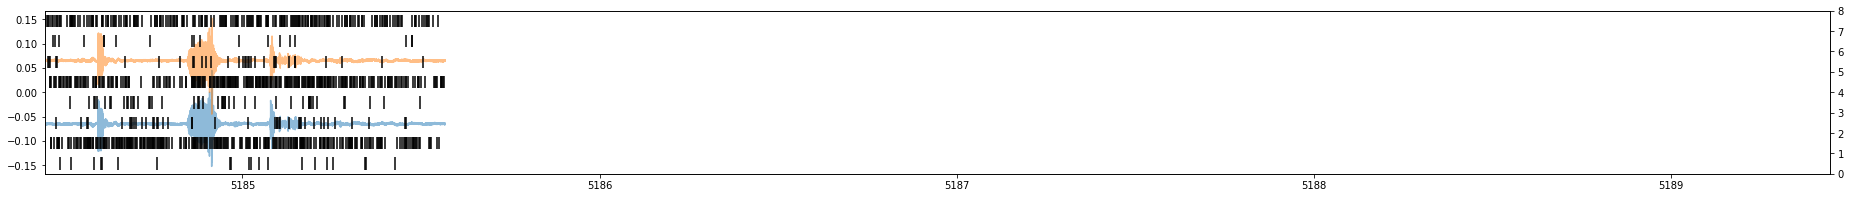

tutor_song_0
111


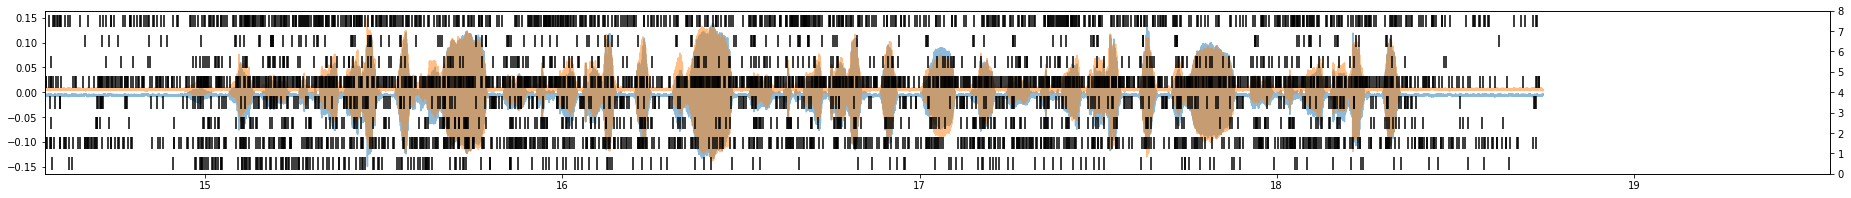

tutor_song_1
112


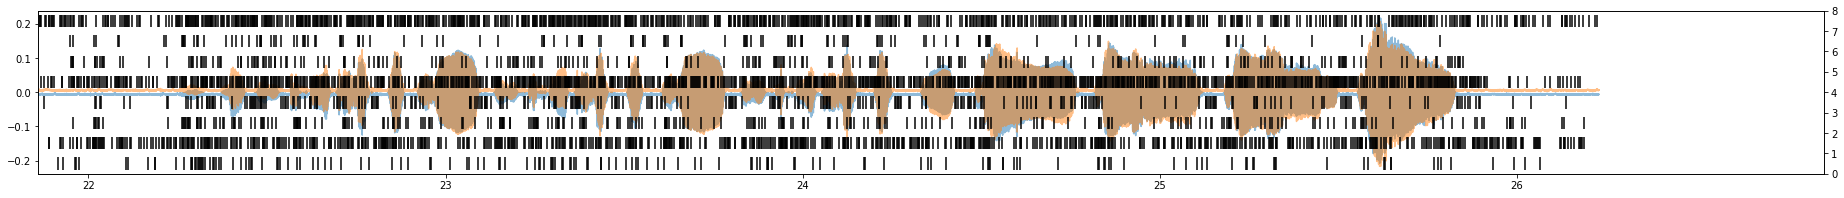

tutor_song_2
113


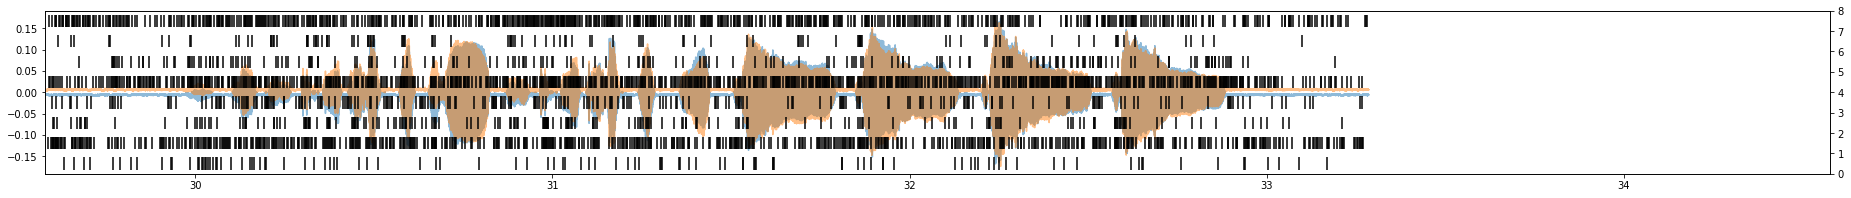

tutor_song_3
114


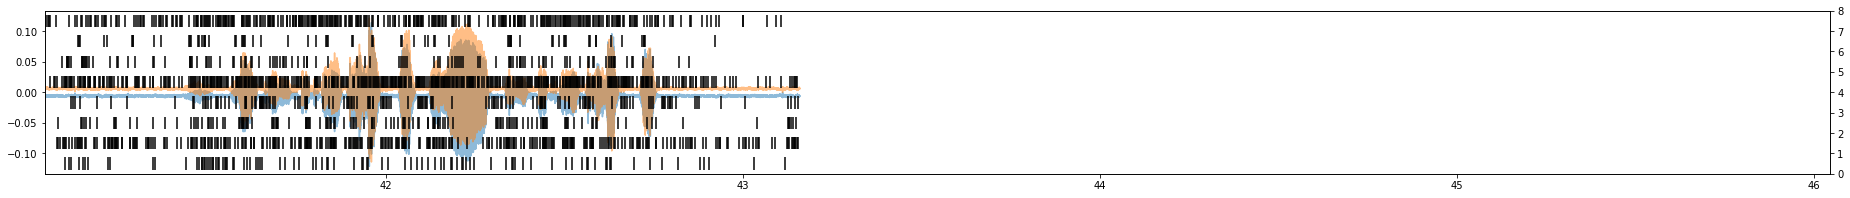

tutor_song_4
115


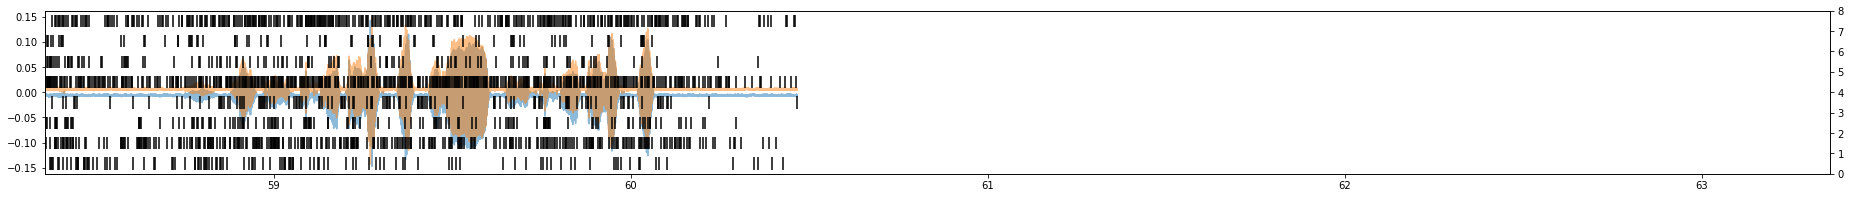

tutor_song_5
116


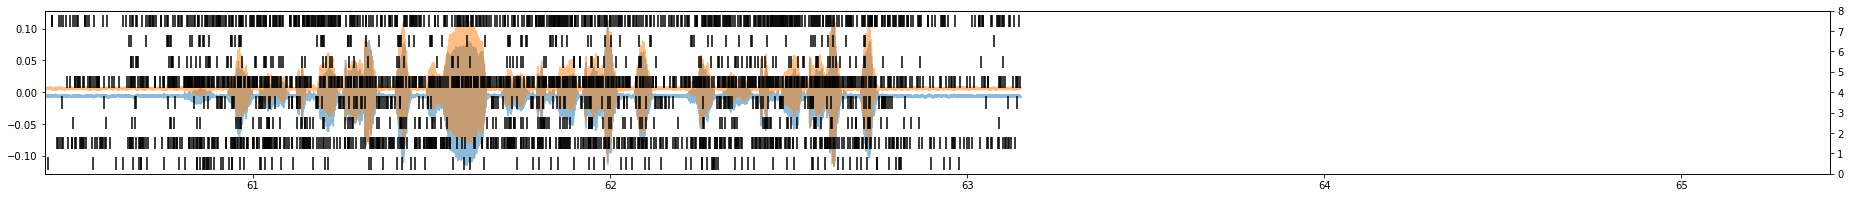

tutor_song_6
117


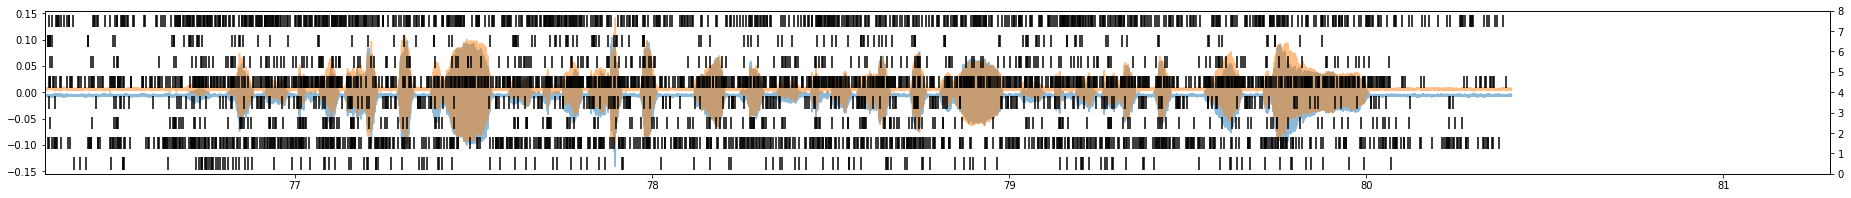

tutor_song_7
118


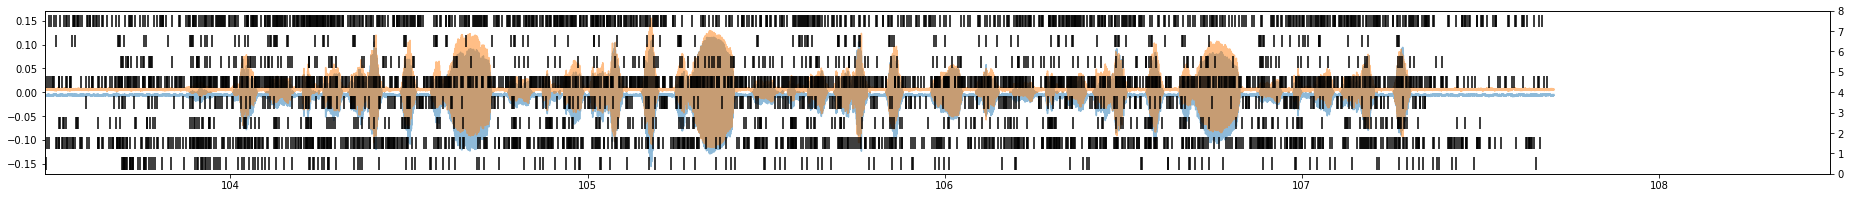

tutor_song_8
119


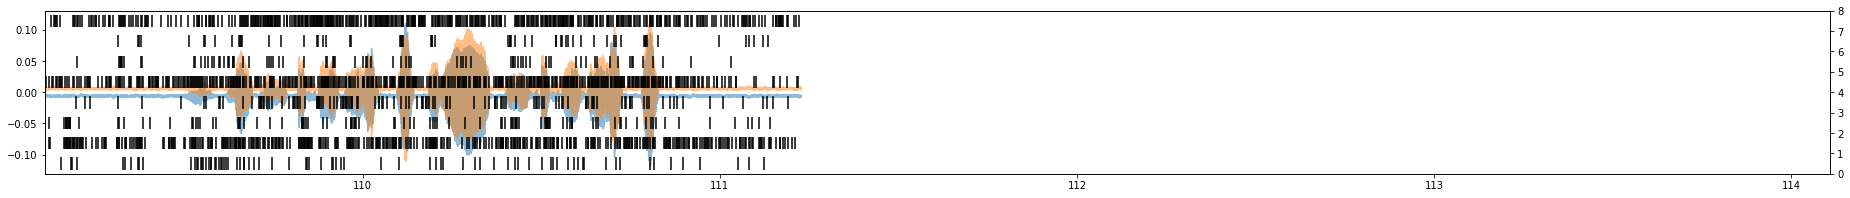

tutor_song_9
120


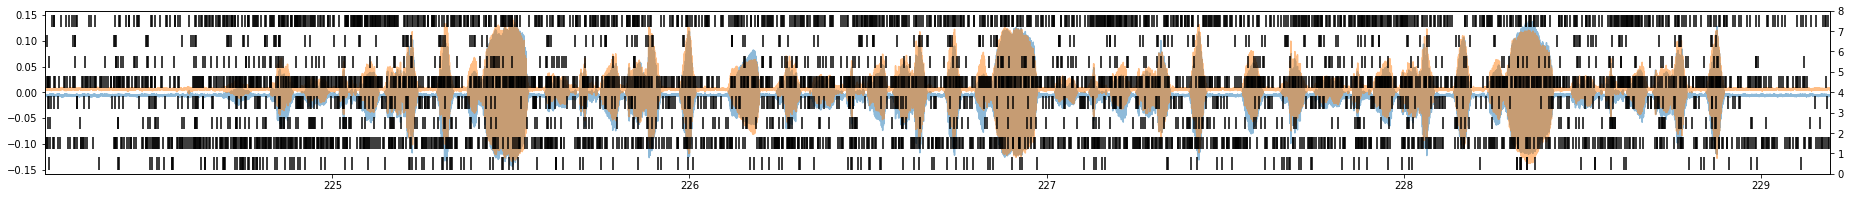

tutor_song_10
121


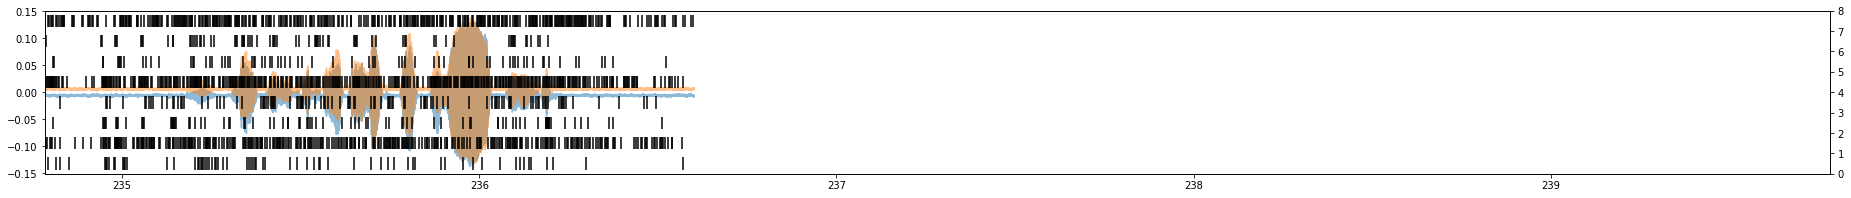

tutor_song_11
122


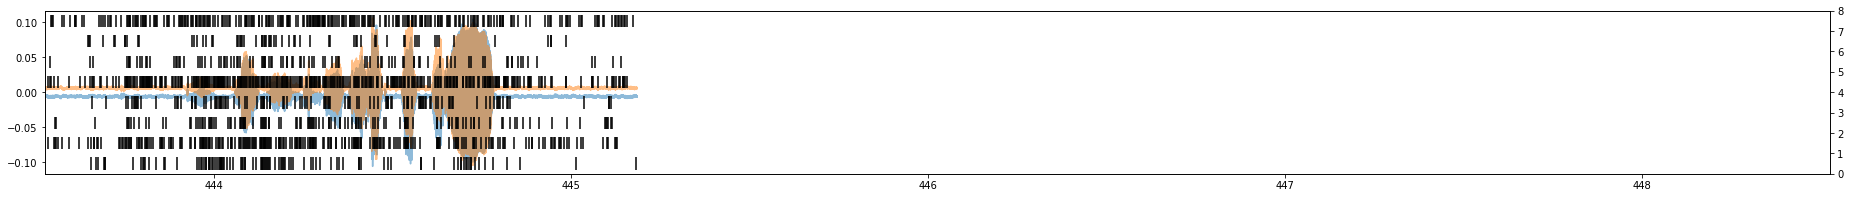

tutor_song_12
123


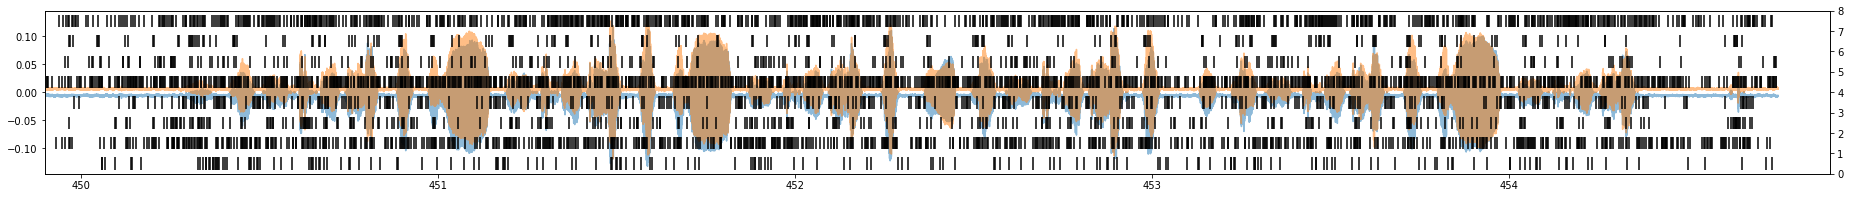

tutor_song_13
124


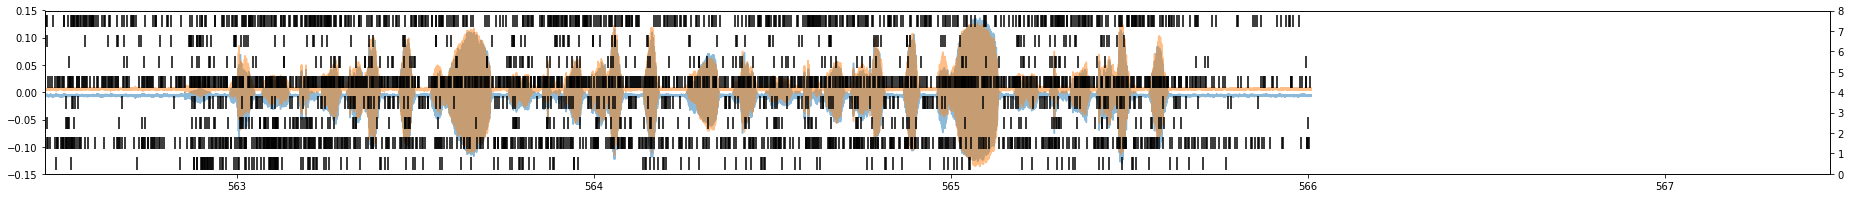

tutor_song_14
125


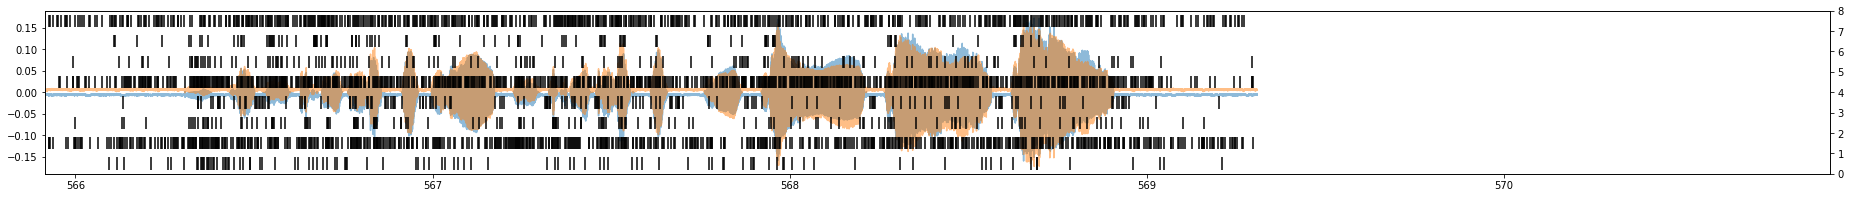

tutor_song_15
126


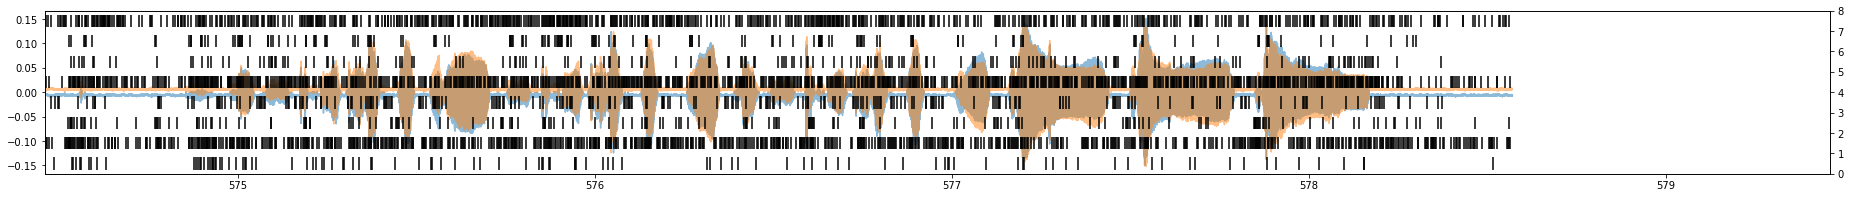

tutor_song_16
127


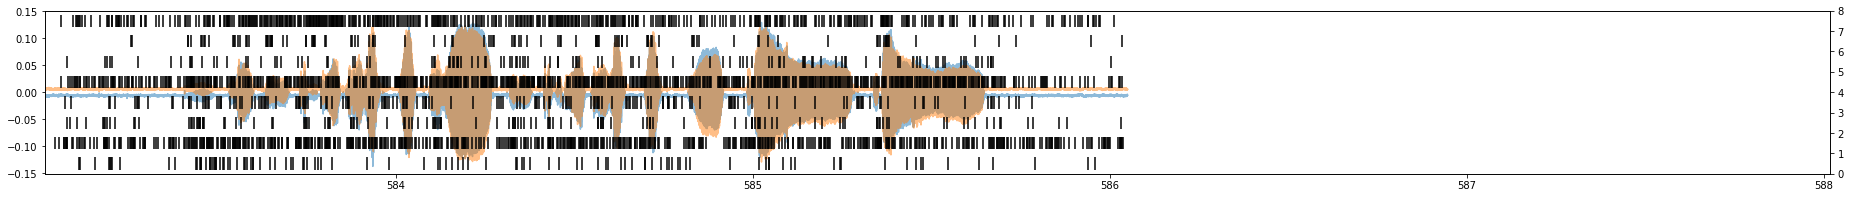

tutor_song_17
128


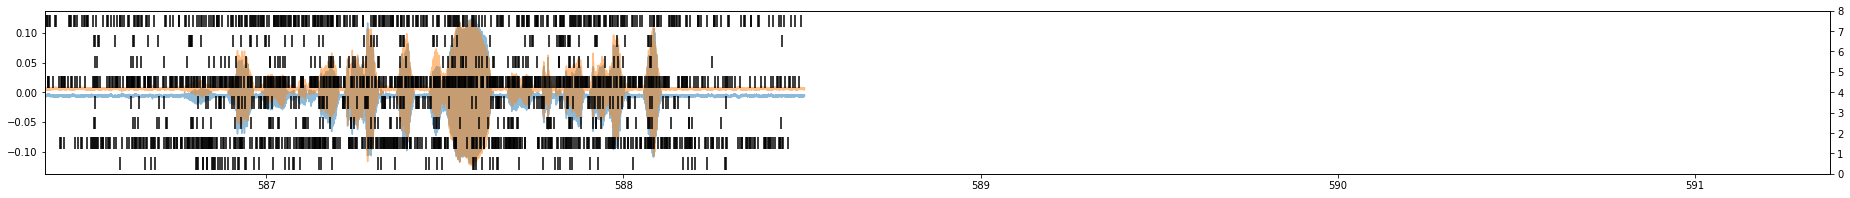

tutor_song_18
129


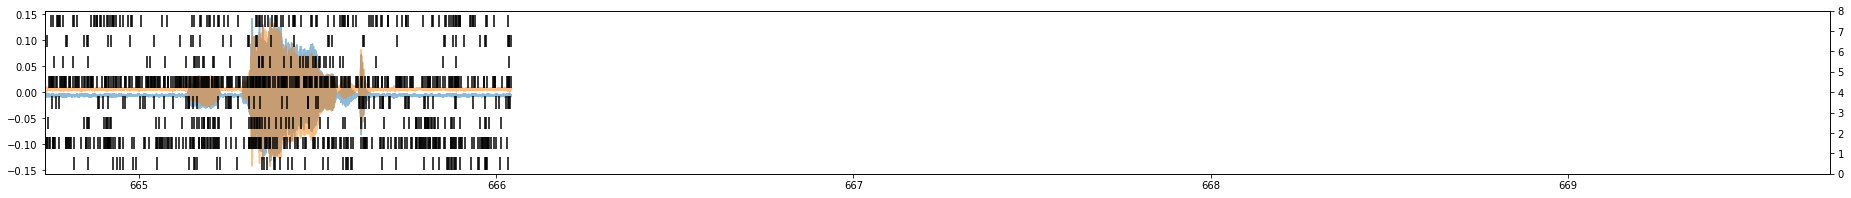

tutor_song_19
130


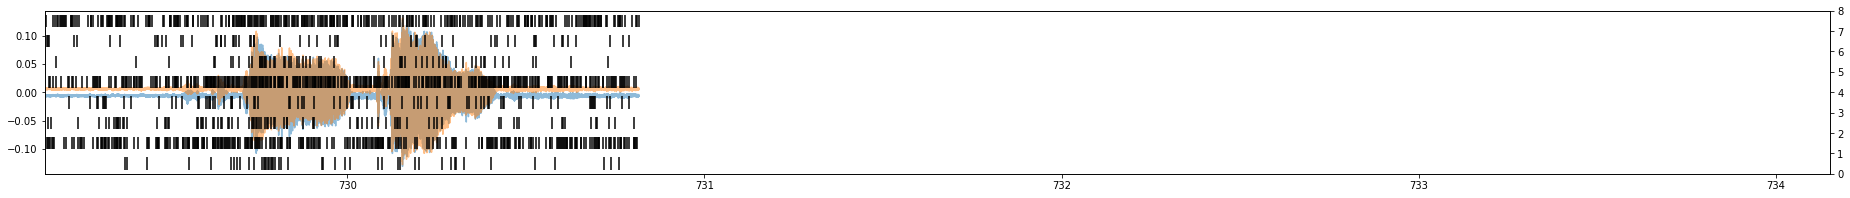

tutor_song_20
131


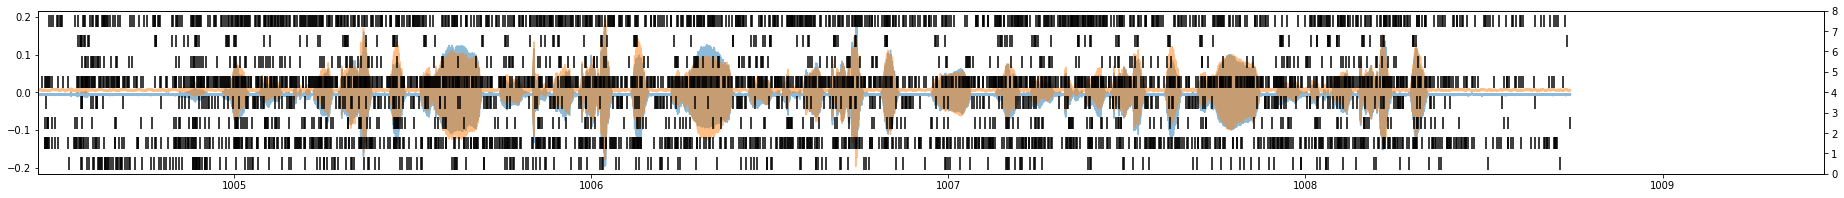

tutor_song_21
132


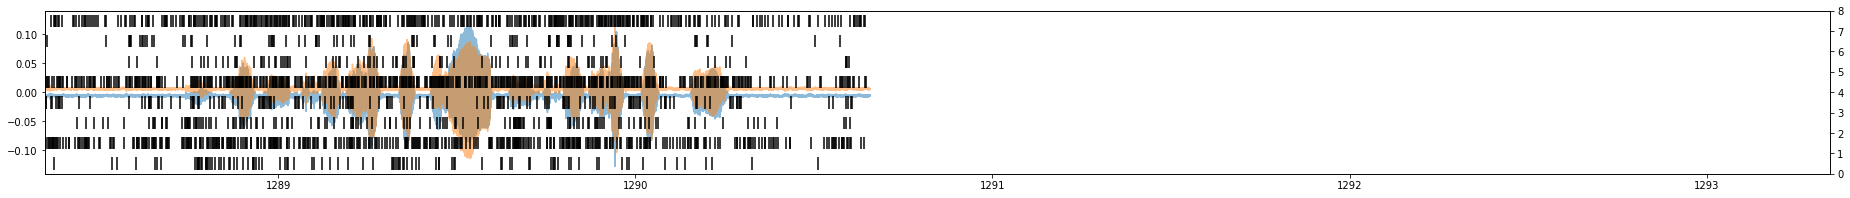

tutor_song_22
133


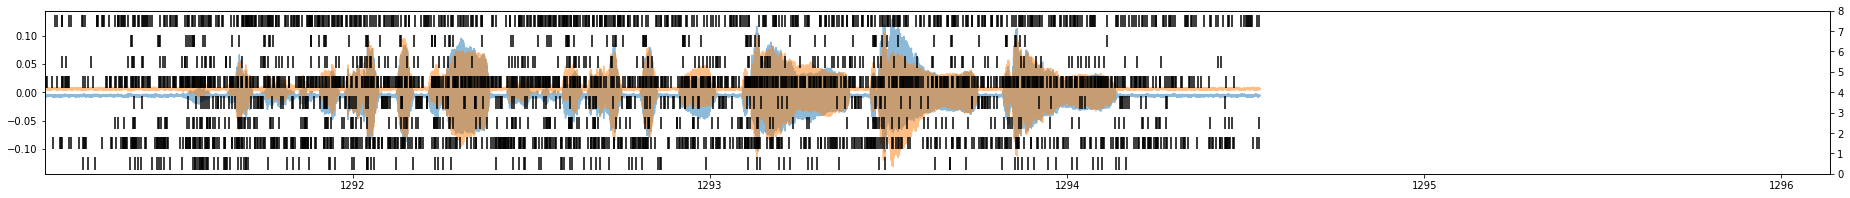

tutor_song_23
134


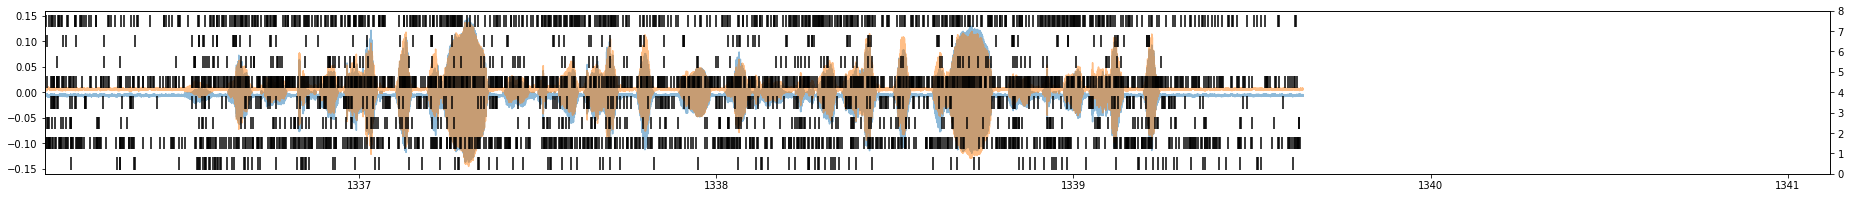

tutor_song_24
135


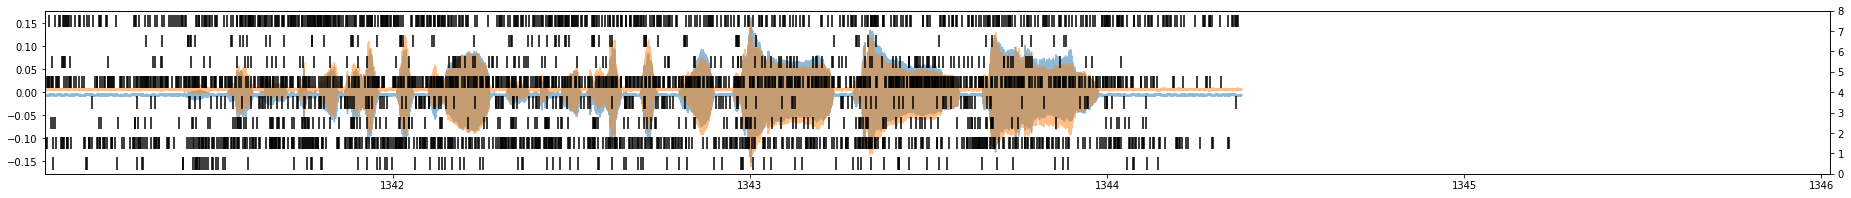

tutor_song_25
136


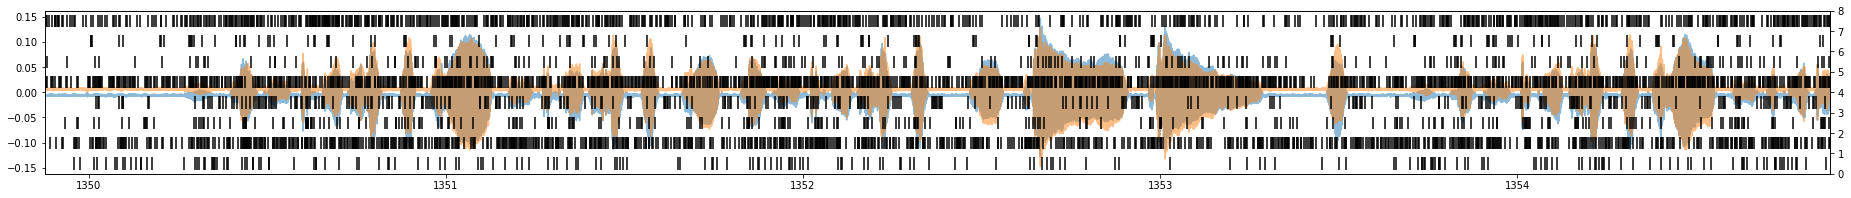

tutor_song_26
137


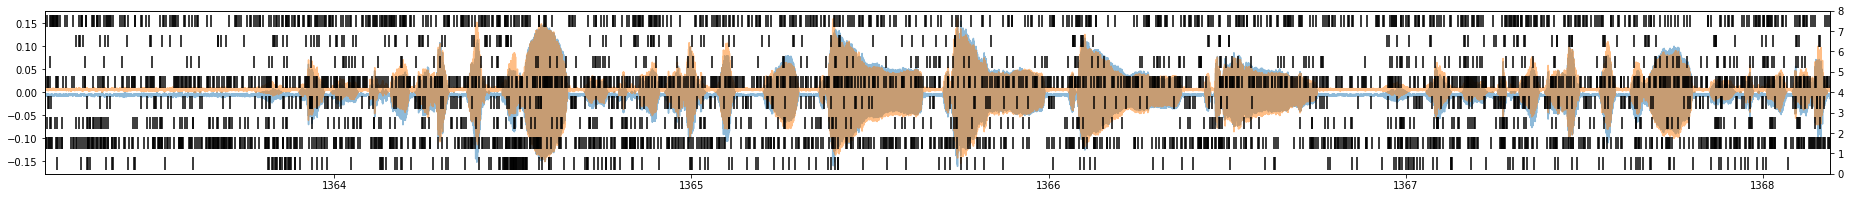

tutor_song_27
138


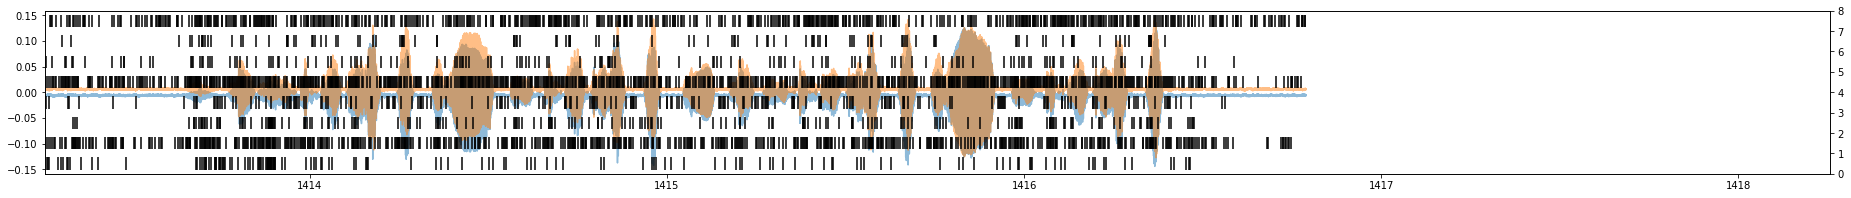

tutor_song_28
139


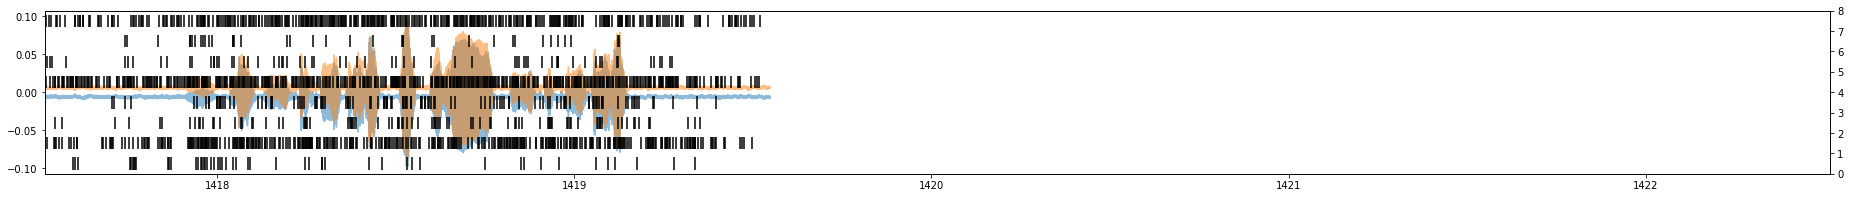

tutor_song_29
140


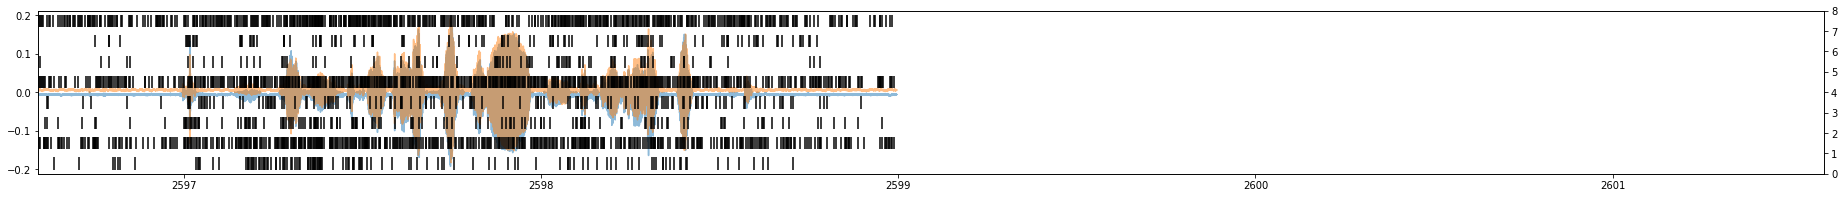

tutor_song_30
141


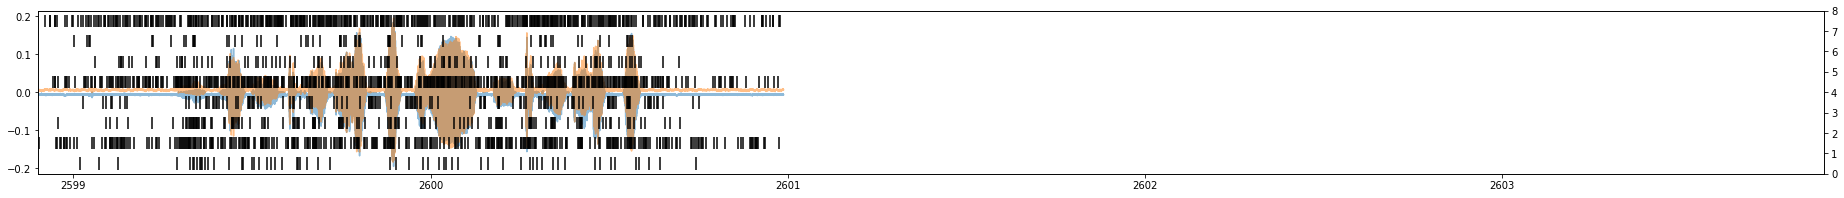

tutor_song_31
142


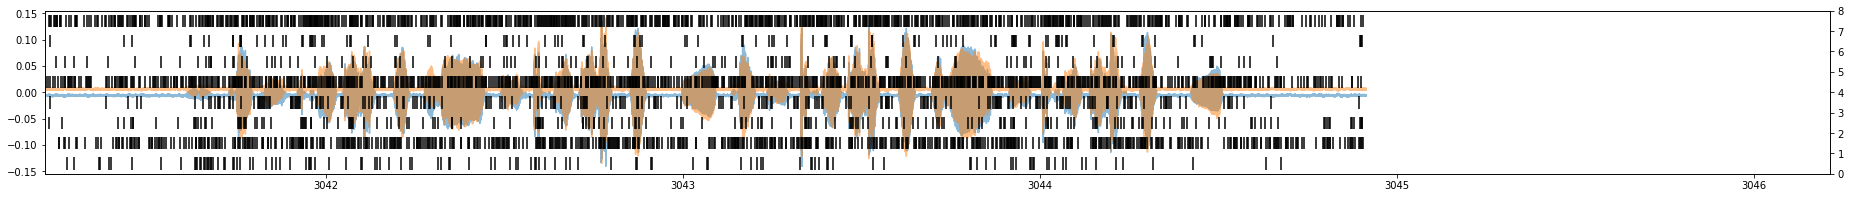

tutor_song_32
143


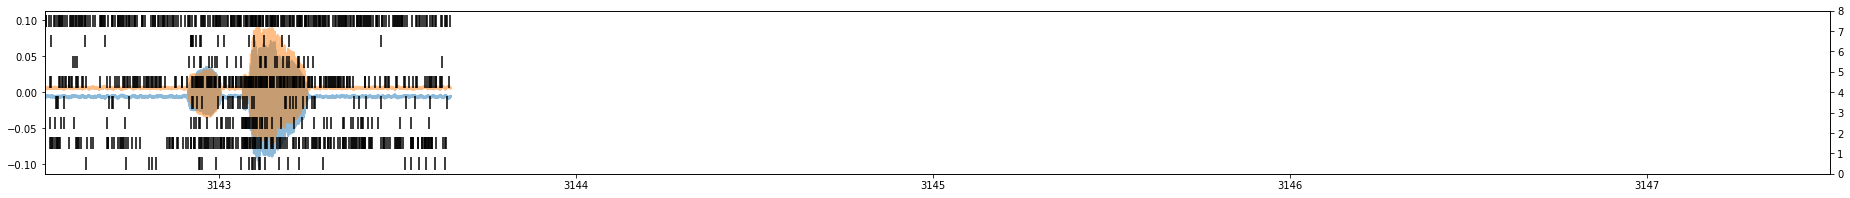

tutor_song_33
144


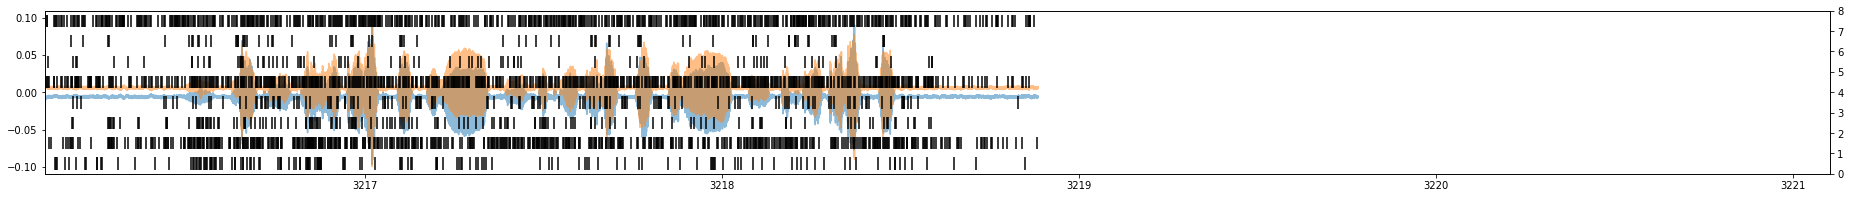

tutor_song_34
145


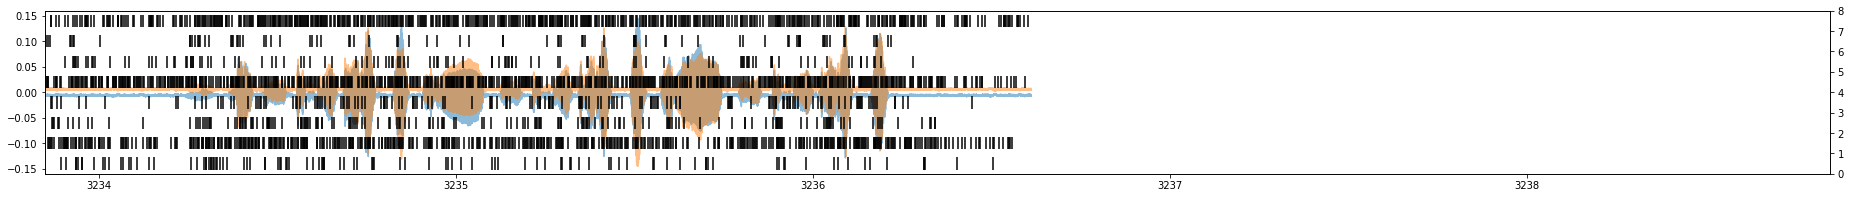

tutor_song_35
146


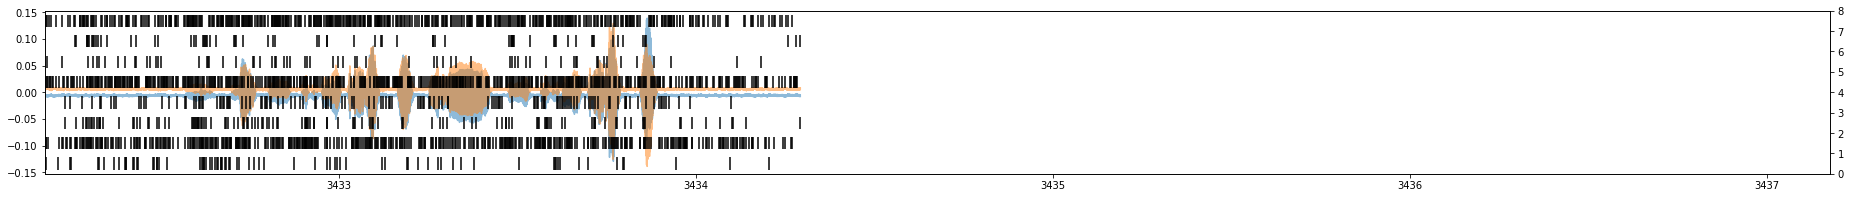

tutor_song_36
147


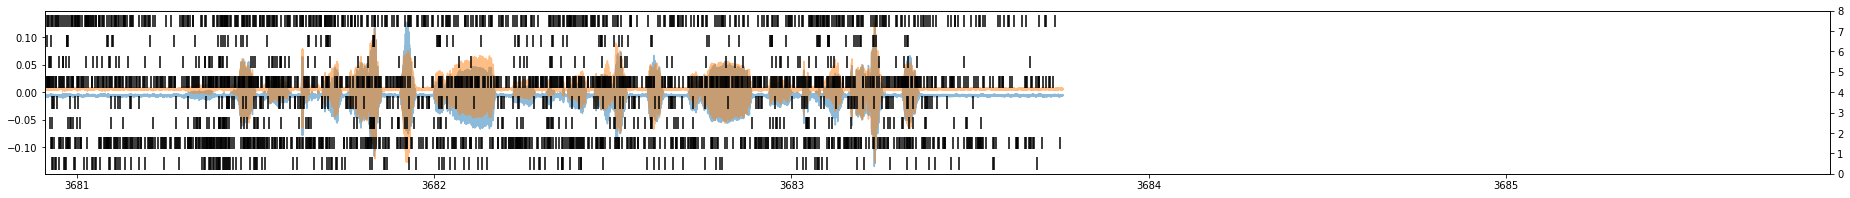

tutor_song_37
148


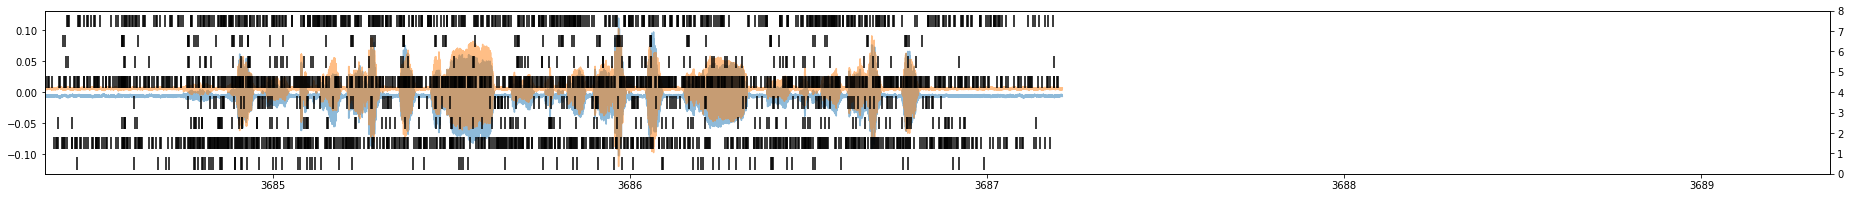

tutor_song_38
149


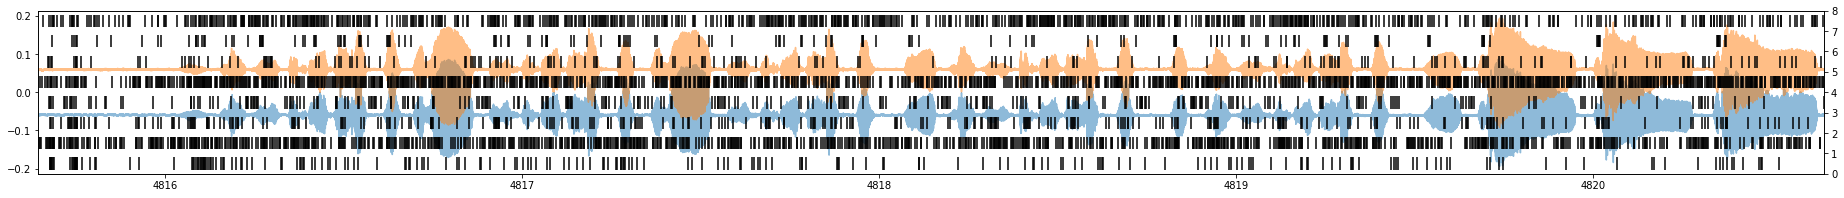

tutor_song_39
150


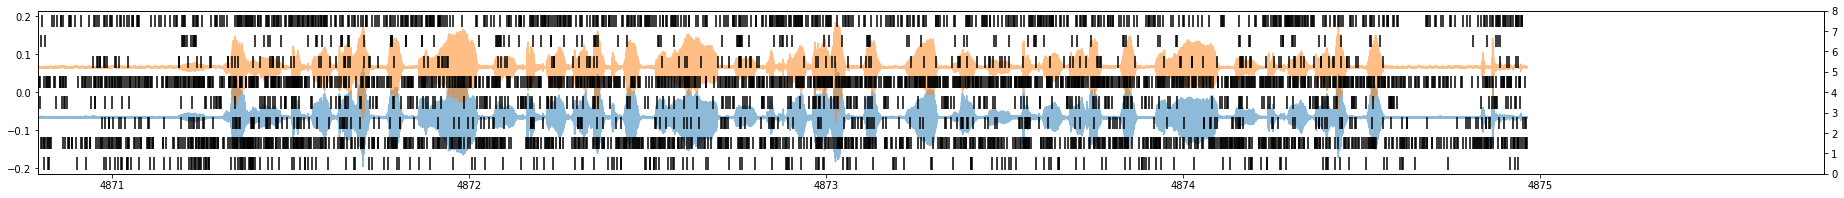

tutor_song_40
151


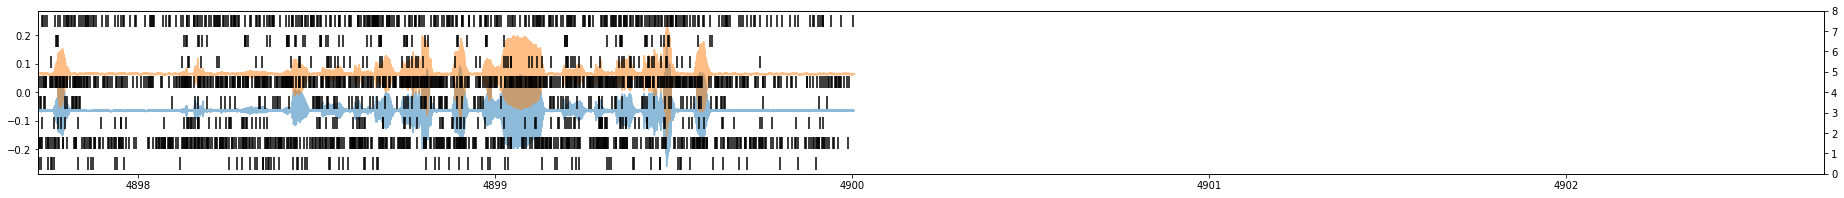

tutor_song_41
152


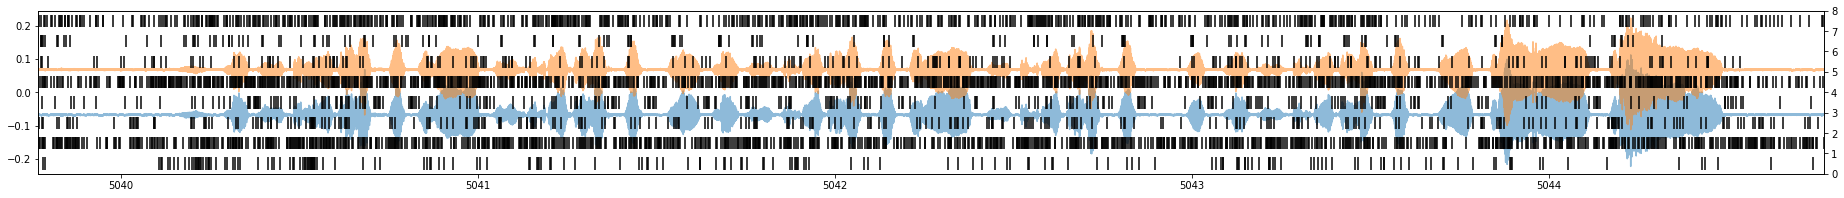

tutor_song_42
153


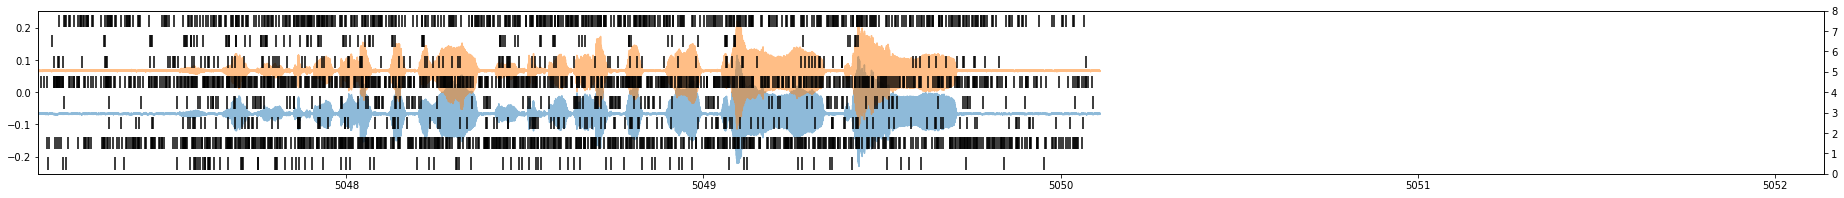

tutor_song_43
154


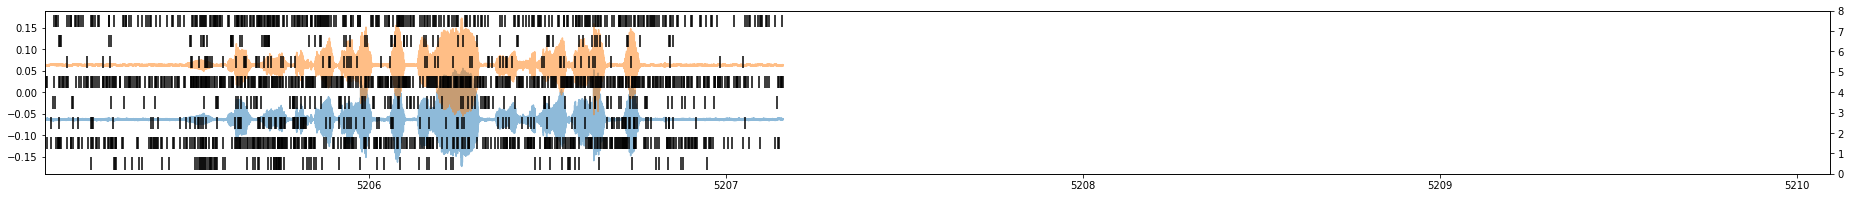

tutor_song_44
155


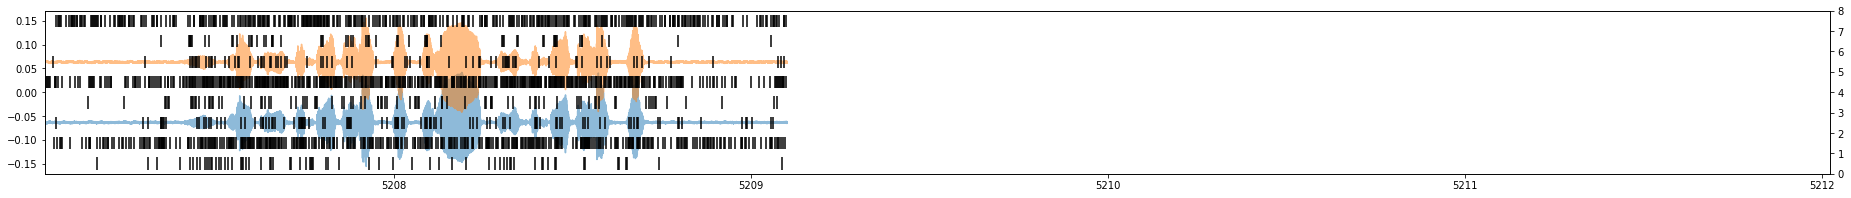

tutor_song_45
156


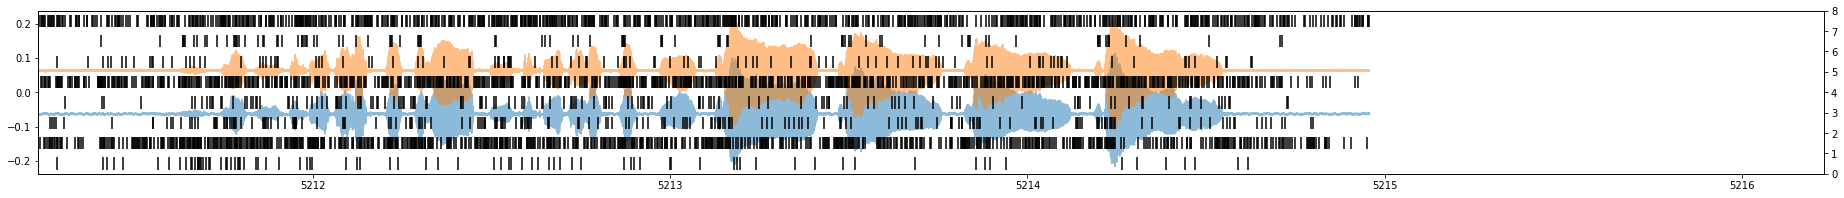

tutor_song_46
157


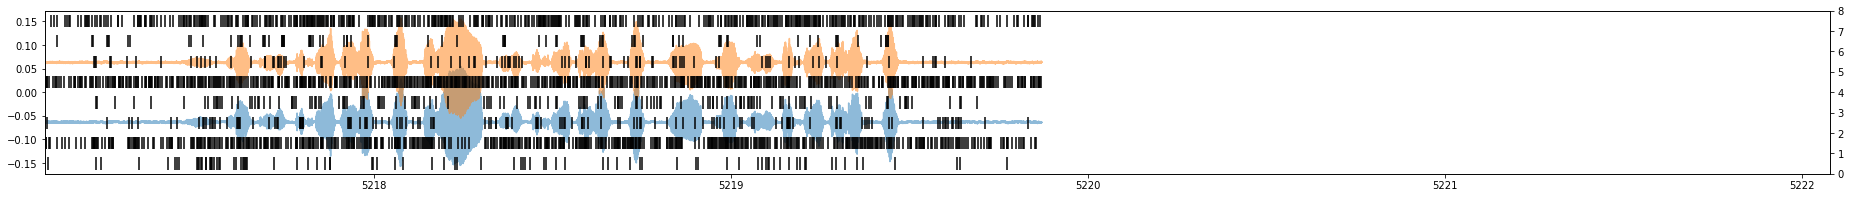

tutor_song_47
158


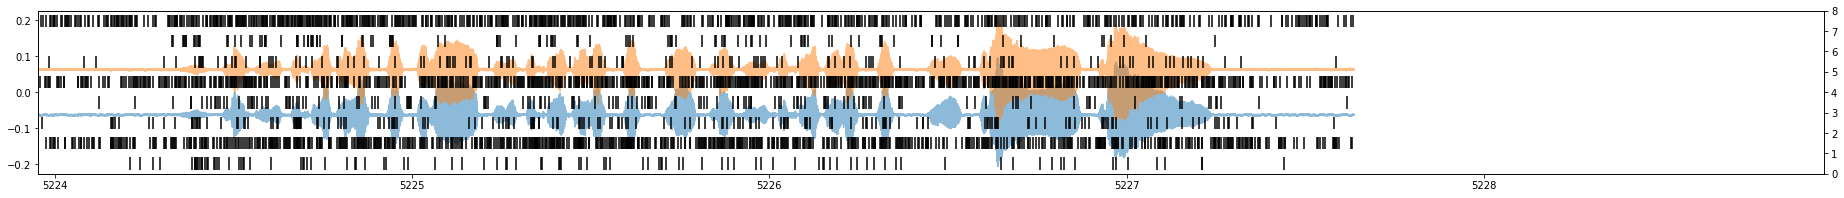

tutor_song_48
159


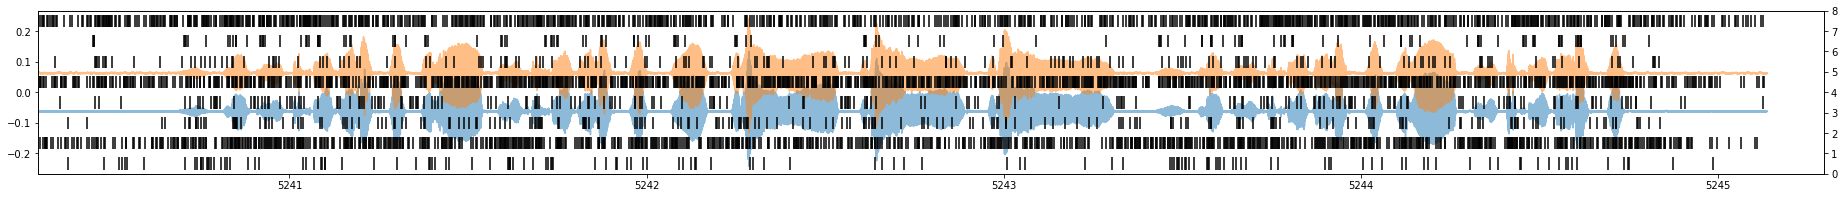

tutor_song_49
160


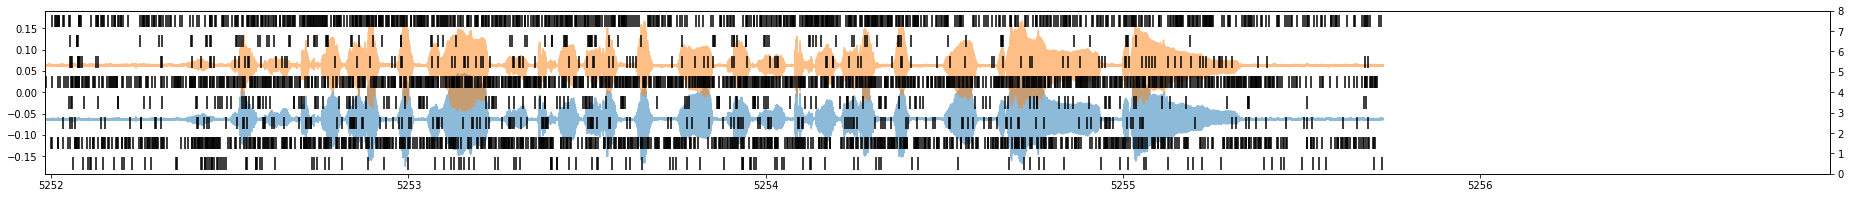

tutor_song_50
161


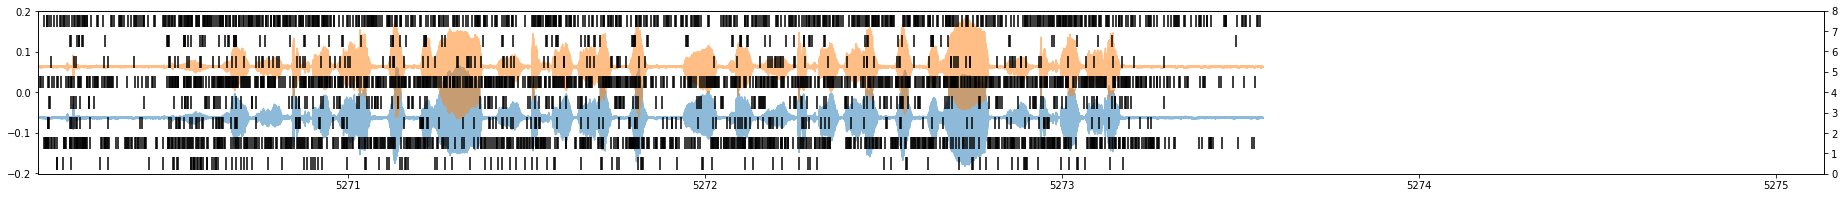

In [12]:
for seg_idx in range(len(spikes_block.segments)):
    
    spikes_seg = spikes_block.segments[seg_idx]
    seg = block.segments[seg_idx]
    
    print seg.name
    print seg_idx
    
    # here we need to figure out which units look reasonable
    
    spiketrains = [st for st in spikes_seg.spiketrains if st.unit.name in {
        "e3u0", "e5u0", "e5u1", "e6u1", "e10u0", "e10u1", "e11u0", "e13u0"
    }]

    sound = seg.analogsignals[0][:, 0]
    sound1 = seg.analogsignals[0][:, 1]
    fig, ax = plt.subplots(figsize=(32, 3))

    plot_spikes_with_timeseries(
        np.linspace(seg.t_start.item(), seg.t_stop.item(), len(sound)),
        spiketrains,
        seg.analogsignals[0].T - np.mean(seg.analogsignals[0].T, axis=0),
        seg.t_start.item(),
        seg.t_start.item() + 5.0,
        ax=ax,
        spike_alpha=1.0,
        y_alpha=[0.5, 0.5]
    )

    plt.show()